In [8]:
# Baixando as bibliotecas necessárias

%pip install pandas --q
%pip install matplotlib --q
%pip install openpyxl --q
%pip install numpy --q
%pip install seaborn --q
%pip install scipy --q
%pip install scikit-learn --q

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [9]:
# Importando as bibliotecas necessárias

# Manipulação de dados e cálculo numérico
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt  # Criação de gráficos
import seaborn as sns            # Heatmaps e gráficos estatísticos

# Pré-processamento e clusterização
from sklearn.preprocessing import StandardScaler  # Padronização z-score
from sklearn.cluster import KMeans                # Algoritmo de agrupamento principal

# Métricas de avaliação dos clusters
from sklearn.metrics import (
    silhouette_score,         # Silhouette médio
    silhouette_samples,       # Silhouette por amostra / por cluster
    davies_bouldin_score,     # Índice de Davies-Bouldin
    calinski_harabasz_score,  # Índice de Calinski-Harabasz (usado na comparação com o Ward)
    adjusted_rand_score,      # ARI: concordância entre agrupamentos
)

# Clusterização hierárquica e distâncias
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster  # Ward e dendrograma
from scipy.spatial.distance import pdist, cdist                    # Distâncias (índice de Dunn)

# Testes estatísticos
from scipy.stats import f_oneway  # ANOVA de uma via

# Etapa 1: Definição da Problemática

 **Problema Principal:** Caracterização dos estilos de jogo dos clubes no Campeonato Brasileiro e a mensuração do retorno em desempenho e do risco associado a cada estilo.

**Adequação ao Agrupamento (Clustering):** A clusterização é adequada para este cenário por se tratar de um problema não supervisionado, no qual não existem rótulos prévios definidos para o "estilo tático" das equipes ao longo de uma temporada completa. O modelo permite extrair grupamentos naturais a partir das estatísticas acumuladas.

**Perguntas Táticas e Estratégicas:**
1. Quais são os perfis/estilos de jogo dominantes praticados pelas equipes no Brasileirão?  
2. Como os times se comportam taticamente quando desconsideramos a disparidade financeira e de força técnica (Elo) entre eles?
3. Qual o binômio "Retorno vs. Risco" (ex.: taxa de pontos e vitórias versus irregularidade e derrotas por goleada) de cada agrupamento tático?   



# Etapa 2: Dataset trabalhado
O conjunto de dados utilizado para análise é derivado do Brasileirão série A, utilizamos um algoritmo para criação de métricas derivadas do dataset original.

## Visão geral

Três tabelas derivadas cobrem o Brasileirão de 2015 a 2023: jogo a jogo (6.838 linhas), time-temporada (180) e time-técnico-temporada (553). Servem de base para clusterizar estilos de jogo e medir retorno e risco de cada um.

- **Origem:** [Brasileirao\_Dataset, de adaoduque](https://github.com/adaoduque/Brasileirao_Dataset) (espelhado no Kaggle). Arquivos usados: `campeonato-brasileiro-full.csv` (jogos, formação, técnico), `campeonato-brasileiro-estatisticas-full.csv` (estatísticas por time e jogo) e `campeonato-brasileiro-gols.csv` (minuto e tipo do gol). O arquivo de cartões foi baixado, mas não entrou nas tabelas.
- **Geração:** script `derivar_metricas_brasileirao.py`.
- **Período:** temporadas 2015–2023, 33 clubes. Antes de 2015 não há estatísticas; 2024 vem sem elas.
- **Temporada:** jogos de jan-mar/2021 pertencem à temporada 2020, que terminou em fev/2021.

| Tabela | Uma linha por | Chave | Linhas | Colunas | Uso recomendado |
| --- | --- | --- | --- | --- | --- |
| `team_match` | time em cada jogo | `ID` + `time` | 6.838 | 84 | Auditoria, modelos jogo a jogo, recálculo de agregações |
| `team_season` | time em cada temporada | `temporada` + `time` | 180 | 57 | Clusterização de estilos; retorno e risco por estilo |
| `team_manager` | técnico em cada time e temporada | `temporada` + `time` + `tecnico` | 553 | 56 | Perfil de treinador; use só linhas com `jogos` ≥ 15 (197 linhas) ou ≥ 30 (60 linhas) |

Cada jogo gera 2 linhas em `team_match` (mandante e visitante): 3.419 jogos no período, sendo 379 em 2016 e 380 em cada uma das outras 8 temporadas. Em `team_season`, 20 clubes por temporada, com 37 ou 38 jogos cada.

## Legenda: team\_match (84 colunas)

Cada linha é um time em um jogo; as colunas `adv_*` trazem o adversário do mesmo jogo. Colunas vazias significam dado não coletado, nunca zero.

### Identificação e contexto

| Coluna | Significado |
| --- | --- |
| `ID` | Código da partida no dataset de origem |
| `temporada` | Ano da temporada (2020 inclui jogos de jan-mar/2021) |
| `data`, `rodada` | Data e rodada do jogo |
| `time`, `adversario` | Clube e seu adversário |
| `casa` | 1 = mandante, 0 = visitante |
| `formacao`, `formacao_adv` | Formação inicial do time e do adversário (ex.: 4-2-3-1) |
| `tecnico`, `tecnico_adv` | Técnico do time e do adversário |
| `gp`, `gc` | Gols pró e gols contra |

### Estatísticas brutas (do time e do adversário, prefixo `adv_`)

| Coluna | Significado | Observação |
| --- | --- | --- |
| `chutes` / `adv_chutes` | Finalizações totais |  |
| `chutes_no_alvo` / `adv_chutes_no_alvo` | Finalizações no alvo | Vazio em 2015 e 2016 (não coletado) |
| `posse_de_bola` / `adv_posse_de_bola` | Posse, em % (0 a 100) | Soma dos dois times ≈ 100 |
| `passes` / `adv_passes` | Passes dados |  |
| `precisao_passes` / `adv_precisao_passes` | Passes certos, em % | Vazio de 2015 a 2017 |
| `faltas` / `adv_faltas` | Faltas cometidas |  |
| `cartao_amarelo`, `cartao_vermelho` (e `adv_`) | Cartões recebidos |  |
| `impedimentos` / `adv_impedimentos` | Impedimentos |  |
| `escanteios` / `adv_escanteios` | Escanteios a favor |  |

### Resultado

| Coluna | Fórmula |
| --- | --- |
| `saldo` | gp − gc |
| `pontos` | 3 (vitória), 1 (empate), 0 (derrota) |
| `vitoria` | 1 se pontos = 3 |
| `derrota_2mais` | 1 se saldo ≤ −2 (cauda de risco) |
| `sem_sofrer`, `sem_marcar` | 1 se gc = 0; 1 se gp = 0 |

### Métricas de estilo derivadas

| Coluna | Fórmula | Leitura |
| --- | --- | --- |
| `chutes_no_alvo_pct` | 100 × chutes\_no\_alvo / chutes | Pontaria |
| `conversao` | 100 × gp / chutes | Gols por chute |
| `conversao_alvo` | 100 × gp / chutes\_no\_alvo | Gols por chute no alvo |
| `chutes_sofridos`, `alvo_sofridos` | adv\_chutes; adv\_chutes\_no\_alvo | Volume defensivo sofrido |
| `gols_por_chute_sofrido_alvo` | 100 × gc / adv\_chutes\_no\_alvo | Eficiência defensiva (inclui goleiro) |
| `part_chutes`, `part_alvo`, `part_passes`, `part_escanteios` | 100 × valor do time / (time + adversário) | Domínio relativo no jogo |
| `passes_certos` | passes × precisao\_passes / 100 | Passes completados |
| `passes_por_posse` | passes / posse\_de\_bola | Proxy de ritmo e jogo direto; não validada |
| `chutes_por_posse` | chutes / posse\_de\_bola | Quanto da posse vira finalização |
| `faltas_sofridas` | adv\_faltas |  |
| `saldo_faltas` | faltas − adv\_faltas | Proxy fraca de intensidade |
| `cartoes` | amarelos + vermelhos |  |

### Formação

| Coluna | Significado |
| --- | --- |
| `f_def` | Defensores (1º número da formação) |
| `f_meio` | Soma dos números intermediários |
| `f_ata` | Atacantes (último número) |
| `tres_zagueiros`, `um_atacante` | 1 se f\_def = 3; 1 se f\_ata = 1 |

### Força do time e forma

| Coluna | Significado |
| --- | --- |
| `elo`, `elo_adv` | Rating Elo antes do jogo (base 1500, K = 20, mando = 60, peso pelo saldo de gols). Parâmetros escolhidos por mim, sem calibração |
| `dif_elo` | elo − elo\_adv |
| `forma_5` | Média de pontos dos 5 jogos anteriores do time (mínimo de 3) |

### Treinador

| Coluna | Significado |
| --- | --- |
| `troca_tecnico` | Verdadeiro se o técnico difere do jogo anterior do time |
| `jogo_do_tecnico` | Nº do jogo daquele técnico no time, contado desde o início do dataset (2003) |

### Gols (arquivo de gols)

| Coluna | Significado |
| --- | --- |
| `n_gols_reg` | Gols registrados no arquivo de gols |
| `gols_75` | Gols aos 75 minutos ou depois (90+3 conta como 93) |
| `gols_1t` | Gols até os 45 minutos (acréscimos 45+x contam como 2º tempo) |
| `gols_penalti`, `gols_contra` | Gols de pênalti; gols contra creditados ao time (assumi que a coluna `clube` indica o time creditado, sem verificar todos os casos) |
| `gols_ok` | Verdadeiro se n\_gols\_reg = gp (100% das linhas no período) |

### Métricas ajustadas pelo adversário (sufixo `_aj`)

| Coluna | Significado |
| --- | --- |
| `posse_de_bola_aj`, `passes_aj`, `precisao_passes_aj`, `chutes_aj`, `chutes_no_alvo_aj`, `escanteios_aj`, `faltas_aj`, `impedimentos_aj`, `part_chutes_aj`, `part_passes_aj`, `passes_por_posse_aj`, `chutes_por_posse_aj` | Resíduo da regressão linear da métrica contra `dif_elo` e `casa`, somado à média geral. Remove o efeito de enfrentar adversário mais forte ou fraco e de jogar em casa |

## Legenda: team\_season (57 colunas)

Cada linha resume a temporada de um clube (180 linhas, 20 clubes por ano). As métricas são médias dos valores jogo a jogo, ignorando jogos vazios, e não razões de somas. Colunas `pct_*` e `risco_derrota_2mais` são proporções de 0 a 1.

### Identificação e amostra

| Coluna | Significado |
| --- | --- |
| `temporada`, `time` | Chave da tabela |
| `jogos` | Jogos do clube na temporada (37 ou 38) |
| `jogos_com_stats` | Jogos com estatística preenchida (mínimo observado: 18; confira antes de usar) |

### Retorno (resultado médio por jogo)

| Coluna | Significado |
| --- | --- |
| `pts_jogo` | Pontos por jogo |
| `saldo_jogo` | Saldo de gols por jogo |
| `gp_jogo`, `gc_jogo` | Gols marcados e sofridos por jogo |

### Risco

| Coluna | Significado |
| --- | --- |
| `risco_pts_dp` | Desvio-padrão dos pontos por jogo (quanto maior, mais irregular) |
| `risco_saldo_dp` | Desvio-padrão do saldo de gols |
| `risco_derrota_2mais` | Proporção de jogos perdidos por 2 ou mais gols |
| `pct_sem_marcar`, `pct_sem_sofrer` | Proporção de jogos sem marcar; sem sofrer gol |
| `pct_vitorias` | Proporção de vitórias |

### Contexto

| Coluna | Significado |
| --- | --- |
| `elo_medio`, `elo_adv_medio` | Força média do time e dos adversários enfrentados (Elo antes do jogo) |
| `f_def`, `f_meio`, `f_ata` | Média de defensores, meias e atacantes nas formações usadas |
| `pct_tres_zagueiros` | Proporção de jogos com 3 zagueiros |
| `formacao_mais_usada` | Formação mais frequente na temporada |
| `n_tecnicos` | Quantidade de técnicos no clube na temporada |
| `tecnico_principal` | Técnico com mais jogos na temporada |

### Estilo (médias; mesma definição de team\_match)

| Colunas | Leitura |
| --- | --- |
| `posse_de_bola`, `passes`, `precisao_passes` | Circulação de bola |
| `chutes`, `chutes_no_alvo`, `chutes_no_alvo_pct`, `conversao` | Finalização |
| `chutes_sofridos`, `alvo_sofridos`, `gols_por_chute_sofrido_alvo` | Defesa (proxy) |
| `part_chutes`, `part_passes`, `part_alvo`, `part_escanteios` | Domínio relativo sobre o adversário |
| `escanteios`, `faltas`, `impedimentos`, `cartoes`, `saldo_faltas` | Volume de eventos |
| `passes_por_posse`, `chutes_por_posse` | Proxies de ritmo e aproveitamento da posse; não validadas |
| `pct_gols_75` | Proporção dos gols marcados aos 75 minutos ou depois |

### Estilo ajustado pelo adversário (sufixo `_aj`)

| Colunas | Significado |
| --- | --- |
| `posse_de_bola_aj`, `passes_aj`, `precisao_passes_aj`, `chutes_aj`, `chutes_no_alvo_aj`, `escanteios_aj`, `faltas_aj`, `impedimentos_aj`, `part_chutes_aj`, `part_passes_aj`, `passes_por_posse_aj`, `chutes_por_posse_aj` | Média da temporada das métricas já descontadas do efeito de força do adversário e mando. Prefira estas ao clusterizar, para que o estilo não vire só "time forte contra time fraco" |

## Legenda: team\_manager (56 colunas)

A tabela tem as mesmas colunas de `team_season`, calculadas por técnico em vez de por clube: só 60 das 553 linhas têm 30 jogos ou mais, então filtre por `jogos` antes de comparar risco.

| Diferença | Detalhe |
| --- | --- |
| Chave | `temporada` + `time` + `tecnico` (a coluna `tecnico` é nova) |
| Colunas removidas | `n_tecnicos` e `tecnico_principal`, que deixam de fazer sentido |
| `jogos` | Jogos daquele técnico naquele clube e temporada: de 1 a 38, mediana 10, média 12,4 |
| `risco_pts_dp`, `risco_saldo_dp` | Vazios quando o técnico comandou 1 jogo (cerca de 16% das linhas), pois o desvio-padrão exige 2 ou mais |
| `pct_gols_75` | Vazio em cerca de 7% das linhas (técnicos cujo time não marcou) |

In [10]:
# Importando base de dados do arquivo CSV
df_manager = pd.read_csv("data/team_manager.csv")
df_match = pd.read_csv("data/team_match.csv")
df_season = pd.read_csv("data/team_season.csv")

# Etapa 3: Análise Exploratória e Preparação da Base de Dados

*Tabela Selecionada:* team_season (Apresenta as métricas que serão utilizadas para clusterização, originalmente com 180 linhas e 57 colunas, representando 20 clubes por ano ao longo de 9 temporadas).

In [11]:
# Verificando quantidade de valores nulos
datasets = {
    'df_season': df_season
}

for nome, conjunto in datasets.items():
  # Calcula os nulos
  missing = conjunto.isna().sum().sort_values(ascending=False)

  # Filtra a Series para manter apenas valores maiores que zero
  missing_filtrado = missing[missing > 0]

  print(f"\n# Dataset '{nome}' possui {missing.sum()} valores nulos.")
  print(f"# Nulos por coluna (apenas colunas com nulos):\n")
  print(missing_filtrado)


# Dataset 'df_season' possui 139 valores nulos.
# Nulos por coluna (apenas colunas com nulos):

precisao_passes                60
precisao_passes_aj             60
gols_por_chute_sofrido_alvo    11
part_alvo                       8
dtype: int64


In [12]:
# Investigando colunas vazias (Se poderá afetar nossa análise)

# Agrupando por temporada
diag = df_season.groupby("temporada").agg(
    times=("time", "nunique"),
    chutes_medio=("chutes", "mean"),
    chutes_alvo_medio=("chutes_no_alvo", "mean"),
    times_com_alvo_zero=("chutes_no_alvo", lambda s: (s == 0).sum()),
    nulos_precisao_passes=("precisao_passes", lambda s: s.isna().sum()),
    nulos_part_alvo=("part_alvo", lambda s: s.isna().sum()),
)

# Proporção de chutes no alvo sobre o total de chutes (bases externas sugerem que em futebol costuma ficar perto de 1/3)
diag["pct_chutes_no_alvo"] = (100 * diag["chutes_alvo_medio"] / diag["chutes_medio"]).round(1)

print(diag.round(2).to_string())

           times  chutes_medio  chutes_alvo_medio  times_com_alvo_zero  nulos_precisao_passes  nulos_part_alvo  pct_chutes_no_alvo
temporada                                                                                                                         
2015          20         12.22               0.25                    5                     20                5                 2.0
2016          20         12.52               0.16                    4                     20                3                 1.3
2017          20         12.77               4.25                    0                     20                0                33.3
2018          20         12.63               3.99                    0                      0                0                31.6
2019          20         13.59               4.47                    0                      0                0                32.9
2020          20         12.62               4.19                    0             

Observa-se que, nas temporadas de **2015 e 2016**, as métricas relacionadas aos chutes apresentam inconsistências, com equipes registrando valores iguais a zero em indicadores como chutes ao alvo, precisão e percentual de chutes, além de resultados inferiores à média geral.

Adicionalmente, nas temporadas de **2015, 2016 e 2017**, identifica-se uma falha na métrica de precisão de passes, com ausência de dados para todas as 20 equipes (100%), comprometendo a análise comparativa desse indicador.

**A seguir, essas inconsistências são apresentadas graficamente**, permitindo visualizar a distribuição dos dados ausentes e dos possíveis valores atípicos ao longo das temporadas analisadas.

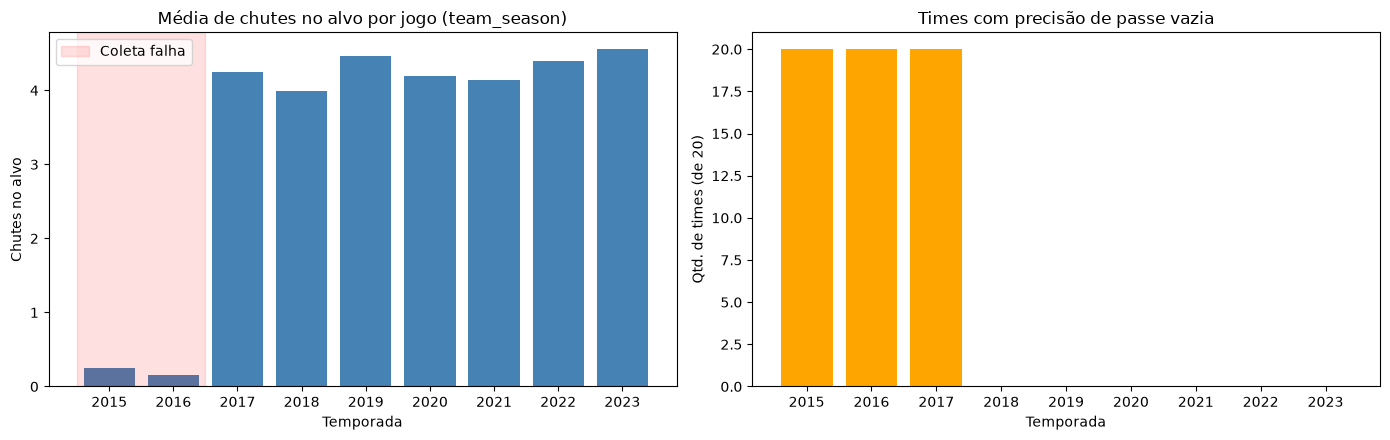

In [13]:
# Gráfico: chutes no alvo e nulos de precisão de passe por temporada

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].bar(diag.index.astype(str), diag["chutes_alvo_medio"], color="steelblue")
ax[0].axvspan(-0.5, 1.5, color="red", alpha=0.12, label="Coleta falha")
ax[0].set_title("Média de chutes no alvo por jogo (team_season)")
ax[0].set_xlabel("Temporada")
ax[0].set_ylabel("Chutes no alvo")
ax[0].legend()

ax[1].bar(diag.index.astype(str), diag["nulos_precisao_passes"], color="orange")
ax[1].set_title("Times com precisão de passe vazia")
ax[1].set_xlabel("Temporada")
ax[1].set_ylabel("Qtd. de times (de 20)")

plt.tight_layout()
plt.show()

Com base nas análises exploratórias realizadas, observa-se a ausência de métricas relevantes nas temporadas de 2015, 2016 e 2017. Para evitar que essas inconsistências comprometam a qualidade dos resultados e a confiabilidade das conclusões, **o estudo será delimitado às temporadas a partir de 2018**, período em que os dados serão considerados para a continuidade das análises. O recorte entre 2018 e 2023 garante a integridade completa das variáveis cruciais de finalização e passe.

In [14]:
# Realizando recorte de temporada (2018 a 2023)
df_season_rec = df_season[(df_season["temporada"] >= 2018)].copy()

In [15]:
# Definição das colunas táticas (Apenas _aj)
colunas_ajustadas = [
    "posse_de_bola_aj", "passes_aj", "precisao_passes_aj", "chutes_aj", "chutes_no_alvo_aj", "escanteios_aj",
    "faltas_aj", "impedimentos_aj", "part_chutes_aj", "part_passes_aj", "passes_por_posse_aj", "chutes_por_posse_aj"
]

# Separar o bloco de performance/identificação
colunas_performance = [
    "temporada", "time", "pts_jogo", "pct_vitorias", "saldo_jogo", "gp_jogo", "gc_jogo", "risco_pts_dp",
    "risco_saldo_dp", "risco_derrota_2mais", "pct_sem_marcar", "pct_sem_sofrer"
]

# Isolamento e Padronização da Matriz de Features
X_style = df_season_rec[colunas_ajustadas].copy()
df_performance = df_season_rec[colunas_performance].copy()




In [16]:
# EDA - Estatísticas descritivas das 12 variáveis de estilo (team_season, 2018-2023)

print(f"Shape da base recortada: {df_season_rec.shape}")
print(f"Times-temporada: {len(df_season_rec)} | Temporadas: {sorted(df_season_rec['temporada'].unique())}")

desc = df_season_rec[colunas_ajustadas].describe().T
desc["cv"] = desc["std"] / desc["mean"]                        # coeficiente de variação
desc["assimetria"] = df_season_rec[colunas_ajustadas].skew()   # skewness
print(desc.round(3))

Shape da base recortada: (120, 57)
Times-temporada: 120 | Temporadas: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
                     count     mean     std      min      25%      50%  \
posse_de_bola_aj     120.0   50.016   3.877   40.973   47.323   49.601   
passes_aj            120.0  424.703  45.153  321.447  394.267  420.373   
precisao_passes_aj   120.0   80.444   2.340   74.337   78.826   80.460   
chutes_aj            120.0   13.109   1.364   10.335   12.185   13.119   
chutes_no_alvo_aj    120.0    4.287   0.577    2.952    3.874    4.278   
escanteios_aj        120.0    5.260   0.709    3.618    4.827    5.250   
faltas_aj            120.0   14.781   1.402   11.063   13.937   14.915   
impedimentos_aj      120.0    1.488   0.341    0.679    1.264    1.462   
part_chutes_aj       120.0   50.003   4.089   38.273   47.805   50.069   
part_passes_aj       120.0   50.016   3.851   40.828   47.269   49.641   
passes_por_posse_aj

In [17]:
# EDA - Valores nulos e duplicados (chave: time + temporada)

nulos = df_season_rec[colunas_ajustadas].isna().sum()
print("--- Nulos nas variáveis de estilo ---")
print(nulos[nulos > 0] if nulos.sum() > 0 else "Nenhum valor nulo nas 12 variáveis de estilo.")

dup_chave = df_season_rec.duplicated(subset=["time", "temporada"]).sum()
dup_linha = df_season_rec.duplicated().sum()
print(f"\nDuplicados por (time + temporada): {dup_chave}")
print(f"Linhas totalmente duplicadas:       {dup_linha}")

print("\n--- Times por temporada ---")
print(df_season_rec.groupby("temporada")["time"].nunique())

--- Nulos nas variáveis de estilo ---
Nenhum valor nulo nas 12 variáveis de estilo.

Duplicados por (time + temporada): 0
Linhas totalmente duplicadas:       0

--- Times por temporada ---
temporada
2018    20
2019    20
2020    20
2021    20
2022    20
2023    20
Name: time, dtype: int64


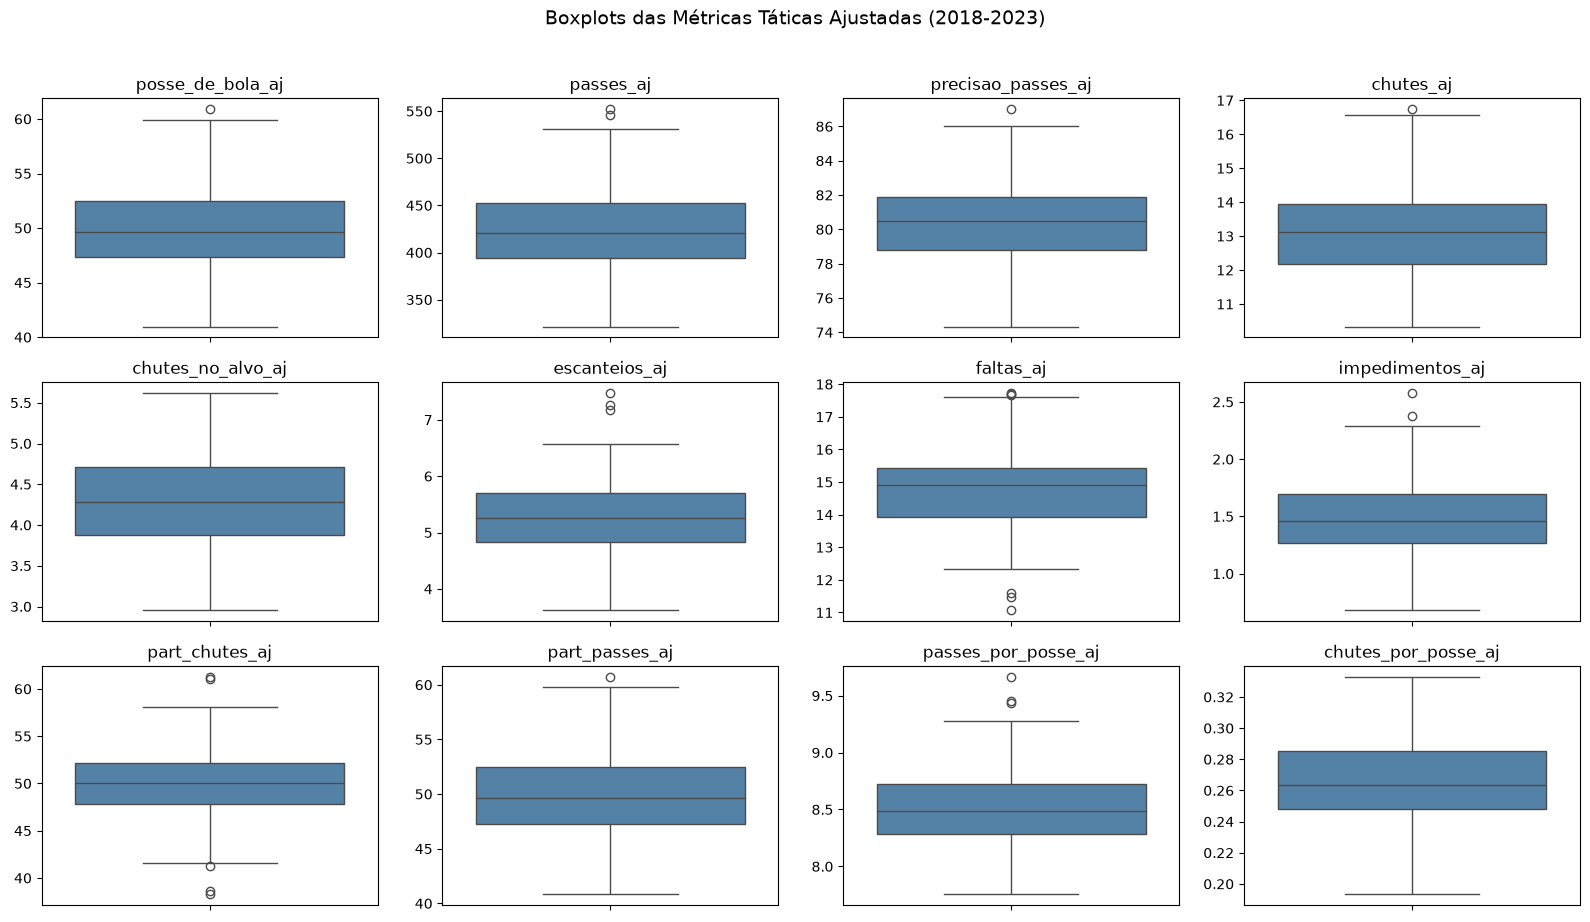

In [18]:
# EDA - Boxplots (1 painel por variável, escalas independentes)

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), colunas_ajustadas):
    sns.boxplot(y=df_season_rec[col], ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("")

plt.suptitle("Boxplots das Métricas Táticas Ajustadas (2018-2023)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [19]:
# EDA - Outliers pelo método IQR (1,5 x amplitude interquartil)

resumo_out = []
detalhe_out = []

for col in colunas_ajustadas:
    q1, q3 = df_season_rec[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df_season_rec[col] < lim_inf) | (df_season_rec[col] > lim_sup)

    resumo_out.append({
        "variavel": col,
        "qtd_outliers": int(mask.sum()),
        "pct": round(100 * mask.mean(), 1),
        "lim_inf": round(lim_inf, 2),
        "lim_sup": round(lim_sup, 2),
    })
    for _, r in df_season_rec[mask].iterrows():
        detalhe_out.append({
            "variavel": col,
            "time": r["time"],
            "temporada": r["temporada"],
            "valor": round(r[col], 2),
        })

df_resumo_out = pd.DataFrame(resumo_out).sort_values("qtd_outliers", ascending=False)
df_detalhe_out = pd.DataFrame(detalhe_out)

print(df_resumo_out.to_string(index=False))

print(f"\nTotal de sinalizações: {len(df_detalhe_out)}")
print(f"Times-temporada distintos com algum outlier: "
      f"{df_detalhe_out.groupby(['time', 'temporada']).ngroups} de {len(df_season_rec)}")

print("\n--- Times-temporada com mais variáveis outlier ---")
print(df_detalhe_out.groupby(["time", "temporada"]).size()
      .sort_values(ascending=False).head(10))

print("\n--- Detalhe dos outliers ---")
print(df_detalhe_out.sort_values("variavel").to_string(index=False))

           variavel  qtd_outliers  pct  lim_inf  lim_sup
          faltas_aj             6  5.0    11.72    17.64
     part_chutes_aj             5  4.2    41.31    58.63
      escanteios_aj             3  2.5     3.53     6.99
passes_por_posse_aj             3  2.5     7.63     9.39
    impedimentos_aj             2  1.7     0.62     2.34
          passes_aj             2  1.7   306.75   540.12
   posse_de_bola_aj             1  0.8    39.57    60.25
 precisao_passes_aj             1  0.8    74.21    86.52
          chutes_aj             1  0.8     9.54    16.60
     part_passes_aj             1  0.8    39.48    60.25
  chutes_no_alvo_aj             0  0.0     2.61     5.98
chutes_por_posse_aj             0  0.0     0.19     0.34

Total de sinalizações: 25
Times-temporada distintos com algum outlier: 18 de 120

--- Times-temporada com mais variáveis outlier ---
time         temporada
Fluminense   2019         4
Atletico-MG  2020         2
Corinthians  2021         2
Bragantino   2023 

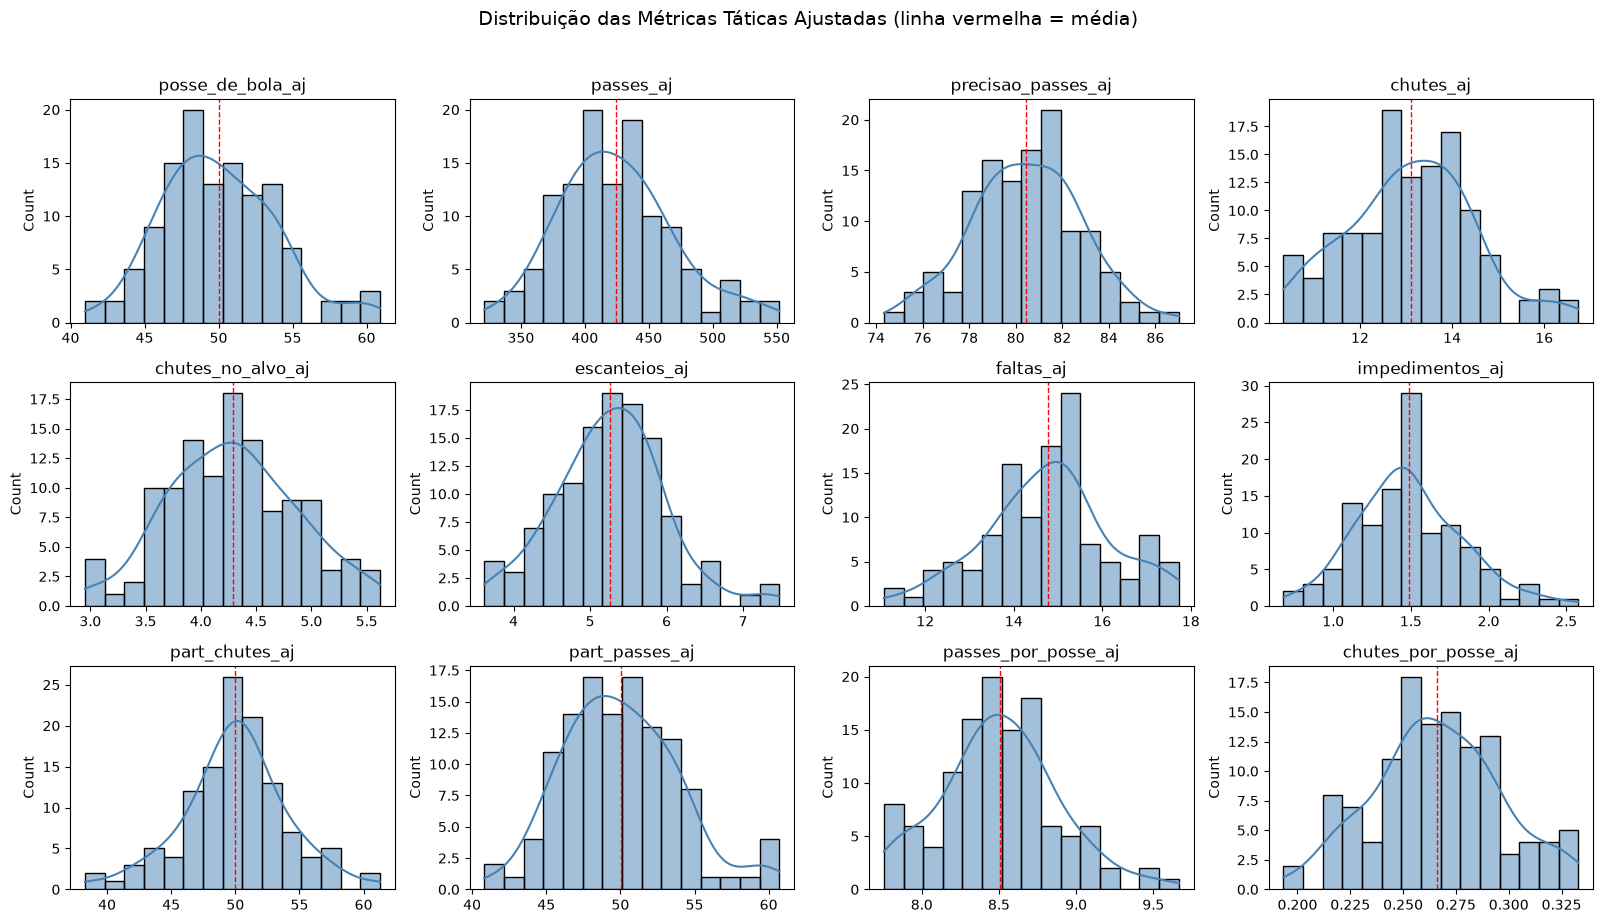

In [20]:
# EDA - Distribuição das variáveis (histograma + densidade)

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), colunas_ajustadas):
    sns.histplot(df_season_rec[col], kde=True, bins=15, ax=ax, color="steelblue")
    ax.axvline(df_season_rec[col].mean(), color="red", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("")

plt.suptitle("Distribuição das Métricas Táticas Ajustadas (linha vermelha = média)",
             y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [21]:
# EDA - Pares de variáveis com correlação forte (|r| >= 0.70)

corr = df_season_rec[colunas_ajustadas].corr()
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack().reset_index())
pares.columns = ["variavel_1", "variavel_2", "correlacao"]

pares_fortes = (pares[pares["correlacao"].abs() >= 0.70]
                .sort_values("correlacao", key=abs, ascending=False))
print(pares_fortes.round(2).to_string(index=False))

        variavel_1          variavel_2  correlacao
  posse_de_bola_aj      part_passes_aj        1.00
         passes_aj      part_passes_aj        0.92
  posse_de_bola_aj           passes_aj        0.91
         passes_aj  precisao_passes_aj        0.88
precisao_passes_aj      part_passes_aj        0.81
  posse_de_bola_aj  precisao_passes_aj        0.81
         chutes_aj   chutes_no_alvo_aj        0.80
         chutes_aj      part_chutes_aj        0.77
         passes_aj passes_por_posse_aj        0.73
         chutes_aj chutes_por_posse_aj        0.71


### Qualidade dos Dados e Estatísticas Descritivas

A base recortada (2018-2023) contém 120 times-temporada, com 20 clubes em cada uma das seis
temporadas. A checagem da chave (`time` + `temporada`) não encontrou duplicados, e as 12 variáveis
de estilo não possuem valores nulos, confirmando que o recorte eliminou as lacunas de
`precisao_passes` e `chutes_no_alvo`.

As estatísticas descritivas mostram escalas bem diferentes entre as variáveis (por exemplo,
`passes_aj` com média próxima de 425 e `impedimentos_aj` próxima de 1,5), o que reforça a
necessidade da padronização antes do clustering. Em termos relativos, a menor dispersão está em
`precisao_passes_aj` (coeficiente de variação de 0,03), indicando que todos os times têm
precisão de passe parecida, e a maior em `impedimentos_aj` (0,23). A posse de bola ajustada
varia de cerca de 41% a 61%, com média de 50%, o que é coerente, já que a posse de um time é
o complemento da do adversário.

### Outliers e Distribuições

Pelo critério do IQR, foram sinalizadas 25 observações em 18 dos 120 times-temporada (15%).
As variáveis com mais ocorrências são `faltas_aj` (6) e `part_chutes_aj` (5). O caso mais
marcante é o Fluminense de 2019, que aparece como outlier em quatro variáveis ligadas à posse
(posse de 60,9%, a maior da base, 552 passes e precisão de 87%). Os demais exemplos também
refletem estilos reais, como o Bragantino de 2023 (muitas finalizações e escanteios), o
Corinthians de 2021 e 2022 (poucas faltas) e o Palmeiras de 2022 e 2023 (muitos impedimentos). Os outliers desses times foram investigados em fontes externas e estão conforme a realidade, os times apresentaram os desempenhos visto no dataset.

Optamos por **manter** esses registros: eles não parecem erros de coleta e representam justamente
os estilos extremos que o clustering deve capturar. Removê-los também reduziria uma amostra que já
é pequena (120 observações). Os histogramas mostram distribuições aproximadamente simétricas
(assimetria entre -0,10 e 0,46), sem caudas pesadas, o que é adequado ao K-Means, que usa distância
euclidiana e funciona melhor com grupos compactos.

### Análise de Desempenho (variáveis de resultado)

Antes de construir os clusters, caracterizamos o desempenho esportivo das equipes. Essas variáveis
**não entram no agrupamento**: o modelo usa apenas variáveis de estilo, e o desempenho será usado
depois, para interpretar o retorno e o risco de cada estilo. Aqui verificamos como os pontos se
distribuem por temporada, criamos a faixa de classificação final de cada time-temporada e
observamos, de forma apenas descritiva, como o estilo se relaciona com o resultado.

           count  mean   std   min   25%   50%   75%   max
temporada                                                 
2018        20.0  1.36  0.36  0.61  1.15  1.29  1.58  2.11
2019        20.0  1.37  0.44  0.53  1.11  1.33  1.66  2.37
2020        20.0  1.36  0.33  0.71  1.10  1.38  1.59  1.87
2021        20.0  1.35  0.36  0.39  1.23  1.32  1.48  2.21
2022        20.0  1.36  0.38  0.58  1.10  1.39  1.55  2.13
2023        20.0  1.37  0.33  0.63  1.18  1.41  1.64  1.84


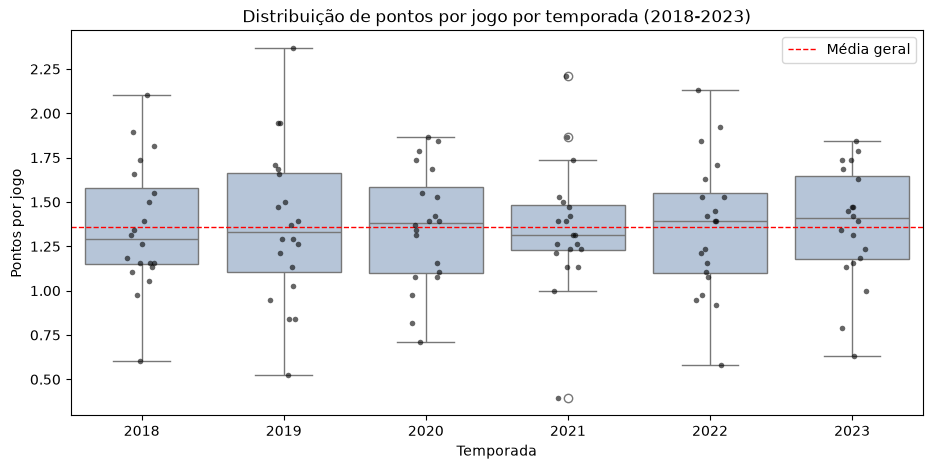

In [22]:
# Desempenho - Distribuição de pontos por jogo em cada temporada

print(df_performance.groupby("temporada")["pts_jogo"].describe().round(2))

plt.figure(figsize=(11, 5))
sns.boxplot(data=df_performance, x="temporada", y="pts_jogo", color="lightsteelblue")
sns.stripplot(data=df_performance, x="temporada", y="pts_jogo", color="black", size=4, alpha=0.6)
plt.axhline(df_performance["pts_jogo"].mean(), color="red", linestyle="--", linewidth=1,
            label="Média geral")
plt.title("Distribuição de pontos por jogo por temporada (2018-2023)")
plt.xlabel("Temporada")
plt.ylabel("Pontos por jogo")
plt.legend()
plt.show()

In [23]:
# Desempenho - Criação da classificação final e da faixa (em df_performance)

# 1. Pontos totais e componentes de desempate (a base traz médias por jogo)
df_performance["jogos"] = df_season_rec["jogos"]
df_performance["pontos"] = (df_performance["pts_jogo"] * df_performance["jogos"]).round().astype(int)
df_performance["vitorias"] = (df_performance["pct_vitorias"] * df_performance["jogos"]).round().astype(int)
df_performance["saldo_total"] = (df_performance["saldo_jogo"] * df_performance["jogos"]).round().astype(int)

# 2. Posição final dentro de cada temporada (pontos > vitórias > saldo de gols)
ordem = df_performance.sort_values(
    ["temporada", "pontos", "vitorias", "saldo_total"],
    ascending=[True, False, False, False]
)
df_performance["posicao_final"] = (
    ordem.groupby("temporada").cumcount().add(1).reindex(df_performance.index)
)

# 3. Faixa de classificação
def classificar_faixa(pos):
    if pos == 1:
        return "Campeão"
    elif pos <= 4:
        return "G4"
    elif pos <= 16:
        return "Meio de tabela"
    return "Z4"

df_performance["faixa_final"] = df_performance["posicao_final"].map(classificar_faixa)
df_performance["faixa_final"] = pd.Categorical(
    df_performance["faixa_final"],
    categories=["Campeão", "G4", "Meio de tabela", "Z4"], ordered=True
)

# 4. Conferência: campeões e rebaixados de cada temporada
print("--- Campeões ---")
print(df_performance[df_performance["posicao_final"] == 1][["temporada", "time", "pontos"]]
      .to_string(index=False))

print("\n--- Rebaixados (Z4) ---")
print(df_performance[df_performance["faixa_final"] == "Z4"]
      .sort_values(["temporada", "posicao_final"])[["temporada", "time", "pontos", "posicao_final"]]
      .to_string(index=False))

print("\n--- Distribuição das faixas ---")
print(df_performance["faixa_final"].value_counts().sort_index())

--- Campeões ---
 temporada        time  pontos
      2018   Palmeiras      80
      2019    Flamengo      90
      2020    Flamengo      71
      2021 Atletico-MG      84
      2022   Palmeiras      81
      2023   Palmeiras      70

--- Rebaixados (Z4) ---
 temporada        time  pontos  posicao_final
      2018       Sport      42             17
      2018  America-MG      40             18
      2018     Vitoria      37             19
      2018      Parana      23             20
      2019    Cruzeiro      36             17
      2019         CSA      32             18
      2019 Chapecoense      32             19
      2019        Avai      20             20
      2020       Vasco      41             17
      2020       Goias      37             18
      2020    Coritiba      31             19
      2020 Botafogo-RJ      27             20
      2021      Gremio      43             17
      2021       Bahia      43             18
      2021       Sport      38             19
     

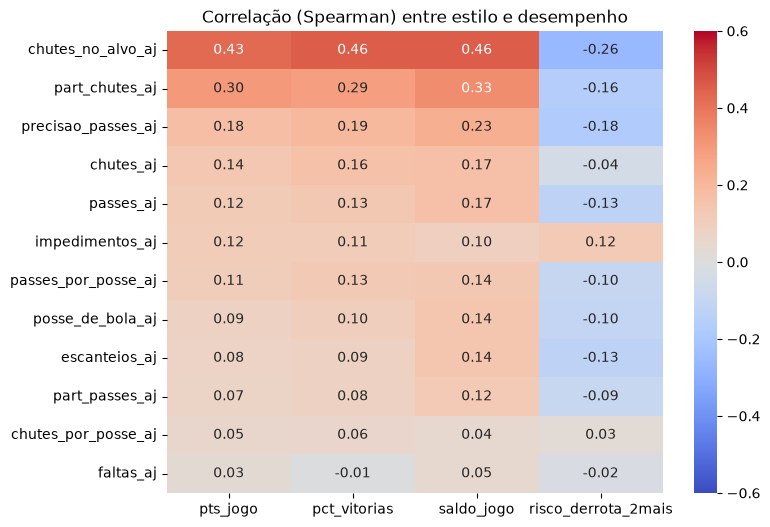

In [24]:
# Desempenho - Correlação descritiva entre estilo e resultado (Spearman)
# Obs.: apenas descritiva; as variáveis de desempenho NÃO entram no clustering.

cols_desempenho = ["pts_jogo", "pct_vitorias", "saldo_jogo", "risco_derrota_2mais"]

base_corr = df_season_rec[colunas_ajustadas].join(df_performance[cols_desempenho])
corr_estilo_desemp = (base_corr.corr(method="spearman")
                      .loc[colunas_ajustadas, cols_desempenho])

plt.figure(figsize=(8, 6))
sns.heatmap(corr_estilo_desemp.sort_values("pts_jogo", ascending=False),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.6, vmax=0.6)
plt.title("Correlação (Spearman) entre estilo e desempenho")
plt.show()

### Resultados da Análise de Desempenho

**Distribuição dos pontos.** A média de pontos por jogo é praticamente igual em todas as
temporadas (cerca de 1,36), o que é esperado, já que os pontos conquistados por um time são
perdidos pelos adversários. O que muda é a dispersão: 2019 teve a maior amplitude (de 0,53 a 2,37
pontos por jogo, com o Flamengo campeão com 90 pontos) e 2023 o campeonato mais equilibrado
no topo (máximo de 1,84, com o campeão fazendo 70 pontos).

**Faixas de classificação.** A posição final foi derivada dos pontos totais (pontos por jogo × 38),
com desempate por vitórias e saldo de gols. Os 120 times-temporada ficaram distribuídos em 6
campeões, 18 em G4 (2º ao 4º), 72 no meio de tabela e 24 no Z4. A conferência manual dos campeões
e rebaixados de cada ano confirma a classificação.

**Estilo e resultado (descritivo).** As correlações são em geral baixas. As variáveis mais ligadas
aos pontos são as de finalização: `chutes_no_alvo_aj` (0,43) e `part_chutes_aj` (0,30). As de posse
e passes mostram relação fraca, como `posse_de_bola_aj` (0,09) e `passes_aj` (0,12), e `faltas_aj`
é praticamente nula (0,03). Ou seja, na amostra, **ter a bola está pouco associado a ganhar pontos,
enquanto finalizar bem está mais associado**. Trata-se de associação, não de causa: a correlação
também pode refletir a qualidade do elenco, mesmo com o ajuste por Elo, adversário e mando.

# Etapa 4: Construção do Clusters

### Escolha do Algoritmo: K-Means

Adotamos o K-Means como método principal por quatro motivos. Primeiro, as 12 variáveis de estilo
são numéricas e contínuas, o que permite usar a distância euclidiana de forma natural. Segundo,
após a padronização, todas passam a ter o mesmo peso de escala. Terceiro, a base é pequena (120
times-temporada para 12 variáveis), e o K-Means é estável nesse cenário e tem um único
hiperparâmetro relevante (o número de clusters k).
Quarto, a interpretação é direta: cada cluster é resumido pelas médias das variáveis, que se traduzem em um perfil de estilo de jogo fácil de explicar à diretoria.

Como limitações, o K-Means assume grupos compactos e é sensível a outliers. Isso é mitigado pelas
distribuições aproximadamente simétricas observadas na EDA e pelo fato de os outliers (18 dos 120
times-temporada) representarem estilos reais, e não erros. Para reduzir a dependência da
inicialização, usamos `n_init=10` e `random_state=42` (reprodutibilidade). Como validação, o resultado é comparado a um segundo método (clusterização hierárquica de Ward).

### Padronização das Features ($Z$-Score)

As variáveis de estilo têm escalas muito diferentes: `passes_aj` tem média em torno de 425, enquanto
`impedimentos_aj` fica perto de 1,5. Como o K-Means calcula distâncias euclidianas, sem padronização
as variáveis de maior magnitude dominariam o agrupamento e as demais quase não influenciariam.
Aplicamos o z-score, que transforma cada variável para média 0 e desvio-padrão 1, de modo que cada
uma contribua na mesma escala e as diferenças passem a ser medidas em desvios-padrão em relação à
média do campeonato.

A padronização é ajustada apenas sobre as 12 variáveis de estilo (`X_style`), antes de anexar o
rótulo do cluster. Ela corrige a escala, mas não a redundância entre variáveis: como posse, passes, precisão e
participação de passes são fortemente correlacionadas, o bloco de posse tende a pesar mais na
separação dos grupos, o que é uma limitação do modelo

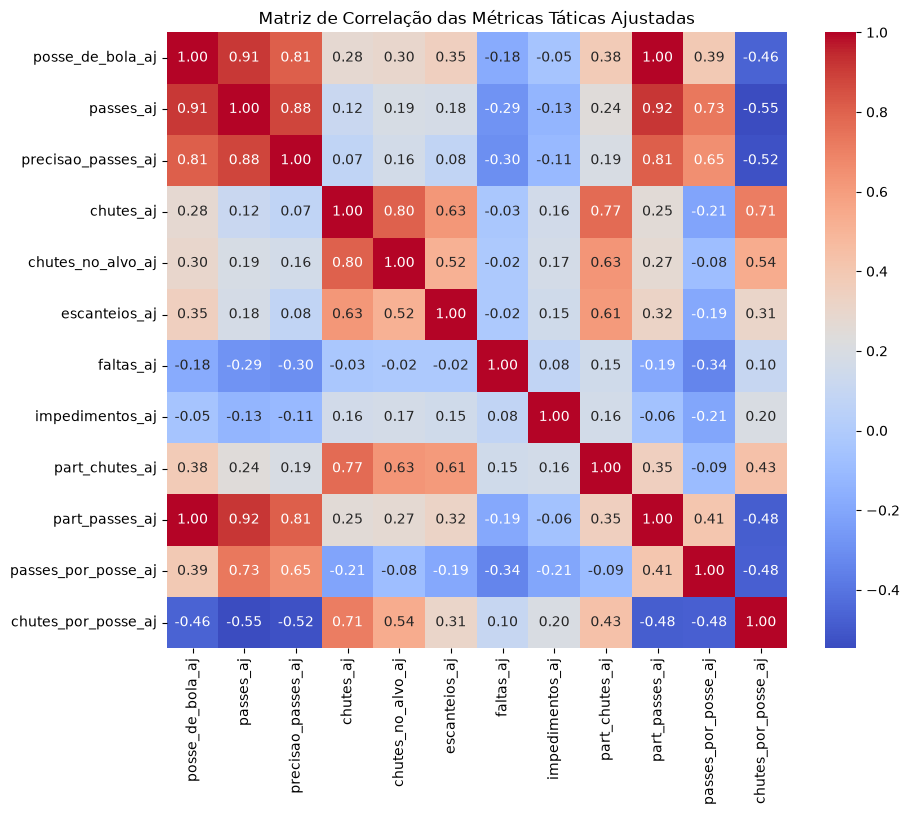

In [25]:
# Visualizar matriz de correlacao entre features taticas
plt.figure(figsize=(10, 8))
sns.heatmap(X_style.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de Correlação das Métricas Táticas Ajustadas")
plt.show()

# Padronizacao Z-Score (Media = 0, Desvio Padrão = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_style)

### Definir o Número Ótimo de Clusters ($K$)

O método do cotovelo não apresenta um ponto de inflexão nítido. A inércia cai de 1.077 (k=2) para
865 (k=3), uma redução de 19,7%, a maior queda marginal depois do k=2; de k=3 para k=4 a queda é de
10,6%, e as seguintes ficam entre 3% e 9%. A Silhouette é maior em k=2 (0,238) e diminui de forma
gradual: 0,209 em k=3 e 0,194 em k=4, ficando abaixo de 0,18 a partir de k=5.

O k=2 é o mais separável estatisticamente, mas separa apenas times de muita posse e passes dos
demais, o que é pouco para o objetivo do projeto, que é diferenciar estilos de jogo para apoiar a
decisão da diretoria. Com k=3, o grupo de menor posse se divide em dois perfis distintos (um com
posse próxima da média e baixo volume de finalização, e outro com menos posse e jogo mais
vertical), com perda de apenas 0,03 de Silhouette. Valores maiores de k reduzem ainda mais a
Silhouette e deixariam grupos com poucos times (cerca de 30 por grupo ou menos em 120 observações).
Por isso escolhemos k=3 como equilíbrio entre qualidade estatística e interpretabilidade.
Reconhecemos que uma Silhouette em torno de 0,21 indica sobreposição entre os grupos, o que é
esperado em estilos de jogo, que formam mais um contínuo do que categorias rígidas.

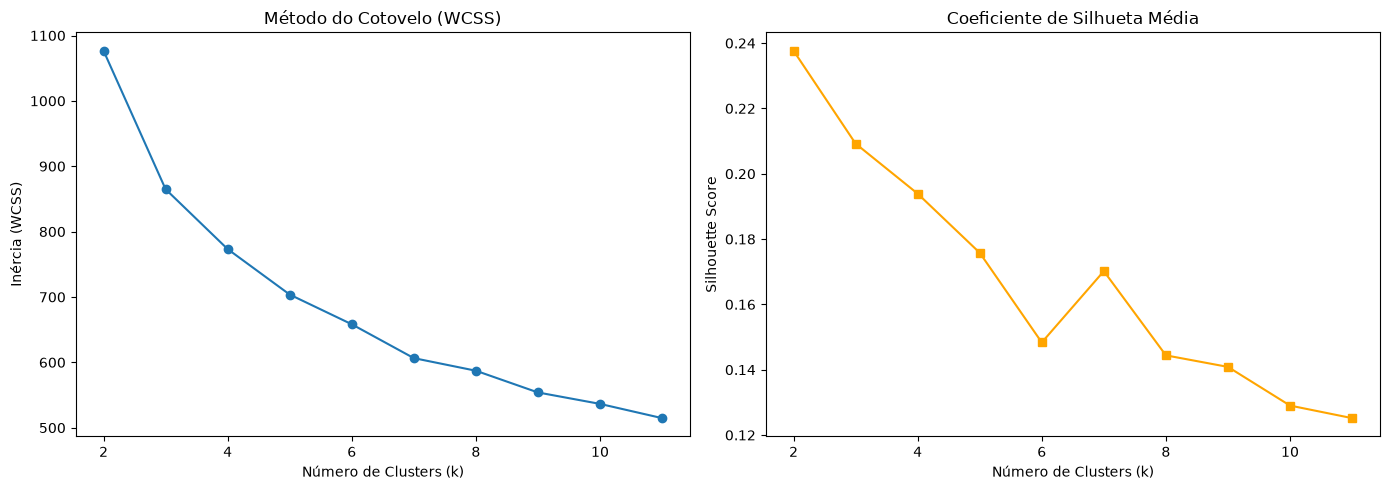

In [26]:
wcss = []
silhouette_scores = []
k_range = range(2, 12)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plotar os dois criterios de avaliacao de K
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(k_range, wcss, marker='o')
ax[0].set_title('Método do Cotovelo (WCSS)')
ax[0].set_xlabel('Número de Clusters (k)')
ax[0].set_ylabel('Inércia (WCSS)')

ax[1].plot(k_range, silhouette_scores, marker='s', color='orange')
ax[1].set_title('Coeficiente de Silhueta Média')
ax[1].set_xlabel('Número de Clusters (k)')
ax[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

### Treinar o Modelo e Anexar os Rótulos

In [27]:
k_otimo = 3

kmeans_final = KMeans(n_clusters=k_otimo, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled)

# Anexar os rotulos nos DataFrames
df_performance['cluster'] = clusters
X_style['cluster'] = clusters

### Validação com Clusterização Hierárquica (Ward)

Para validar a escolha, aplicamos a clusterização hierárquica aglomerativa com o critério de Ward,
que minimiza o aumento da variância dentro dos grupos (critério próximo ao do K-Means, o que
torna a comparação justa). No dendrograma, a maior distância ocorre na última fusão (26,6, contra
17,6 na anterior), indicando que a separação mais forte é em **dois** grupos; a fusão seguinte
(17,6 contra 13,6) sustenta o corte em três grupos de forma menos evidente.

Comparando com o K-Means pelo Adjusted Rand Index (ARI), os métodos concordam quase totalmente em
k=2 (0,90) e de forma moderada em k=3 (0,47). O ponto mais importante é que o grupo dominante é
robusto: os 35 times do cluster de maior posse e passes do K-Means caem todos no mesmo grupo do
Ward. Já a divisão entre os dois grupos restantes difere (o Ward produz grupos desbalanceados, de
43, 15 e 62 times). Concluímos que a separação entre times de alta posse e os demais é consistente
entre os métodos, enquanto a fronteira entre os dois perfis de menor posse é menos nítida, e por
isso sua interpretação deve ser feita com cautela. Mantemos o K-Means com k=3 como modelo
principal, por produzir grupos mais equilibrados (41, 35 e 44) e mais fáceis de interpretar.

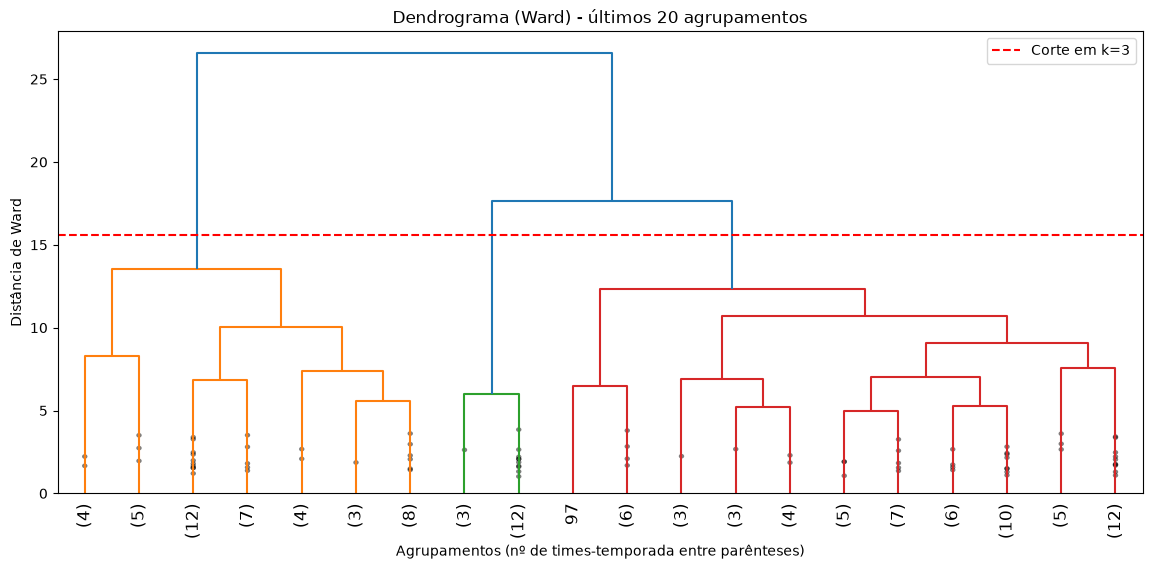

Alturas das últimas fusões: [10.1 10.7 12.3 13.6 17.6 26.6]
 k  silhouette_ward  davies_bouldin_ward  calinski_harabasz_ward  ARI_vs_kmeans      tamanhos_ward
 2            0.227                1.569                  38.252          0.901           [43, 77]
 3            0.183                1.403                  31.876          0.469       [43, 15, 62]
 4            0.170                1.469                  27.598          0.393    [9, 34, 15, 62]
 5            0.153                1.441                  25.436          0.376 [9, 34, 15, 7, 55]

K-Means (linhas) x Ward (colunas), k=3:
Ward      0   1   2
K-Means            
0         5  15  21
1        35   0   0
2         3   0  41


In [28]:
# Validação - Clusterização hierárquica (Ward) e dendrograma
Z = linkage(X_scaled, method="ward")

# Corte entre a fusão que cria 3 clusters e a que cria 2
corte_k3 = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90,
           show_contracted=True, color_threshold=corte_k3)
plt.axhline(corte_k3, color="red", linestyle="--", label="Corte em k=3")
plt.title("Dendrograma (Ward) - últimos 20 agrupamentos")
plt.xlabel("Agrupamentos (nº de times-temporada entre parênteses)")
plt.ylabel("Distância de Ward")
plt.legend()
plt.show()

print("Alturas das últimas fusões:", Z[-6:, 2].round(1))

# Comparação Ward x K-Means para k de 2 a 5
linhas = []
for k in range(2, 6):
    lab_w = fcluster(Z, k, "maxclust") - 1
    lab_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    linhas.append({
        "k": k,
        "silhouette_ward": silhouette_score(X_scaled, lab_w),
        "davies_bouldin_ward": davies_bouldin_score(X_scaled, lab_w),
        "calinski_harabasz_ward": calinski_harabasz_score(X_scaled, lab_w),
        "ARI_vs_kmeans": adjusted_rand_score(lab_k, lab_w),
        "tamanhos_ward": np.bincount(lab_w).tolist(),
    })
print(pd.DataFrame(linhas).round(3).to_string(index=False))

# Cruzamento detalhado em k=3
labels_ward3 = fcluster(Z, 3, "maxclust") - 1
print("\nK-Means (linhas) x Ward (colunas), k=3:")
print(pd.crosstab(clusters, labels_ward3, rownames=["K-Means"], colnames=["Ward"]))

# Etapa 5: Avaliação de Clusters
### Avaliação Interna dos Clusters

Nesta etapa avaliamos a qualidade do agrupamento com as métricas internas vistas em aula, que usam
apenas os dados, sem rótulos verdadeiros: o **método do cotovelo (inércia)**, o **Silhouette**, o
**índice de Dunn** e o **índice de Davies-Bouldin**. O cotovelo e o Silhouette já foram usados na
Etapa 4 para escolher o k; aqui eles são consolidados com o Dunn e o Davies-Bouldin, comparando k
de 2 a 6, para verificar se o k=3 se sustenta em mais de uma métrica.

- **Inércia (↓):** soma dos quadrados intra-cluster; sempre diminui com k, e procura-se o ponto em
  que a queda perde força (cotovelo).
- **Silhouette (↑):** compara a proximidade de cada ponto ao próprio cluster e ao cluster vizinho (de -1 a +1).
- **Dunn (↑):** menor distância entre clusters dividida pelo maior diâmetro dentro de um cluster.
- **Davies-Bouldin (↓):** similaridade média, no pior caso, entre cada cluster e seu vizinho mais parecido.

   Inércia (↓)  Silhouette (↑)  Dunn (↑)  Davies-Bouldin (↓)                  Tamanhos  Queda da inércia (%)
k                                                                                                           
2     1076.744           0.238     0.136               1.543                  [78, 42]                   NaN
3      864.866           0.209     0.152               1.452              [41, 35, 44]                  19.7
4      773.269           0.194     0.142               1.420          [37, 33, 37, 13]                  10.6
5      703.710           0.176     0.176               1.540      [18, 11, 27, 29, 35]                   9.0
6      658.268           0.148     0.140               1.600  [25, 28, 26, 12, 13, 16]                   6.5


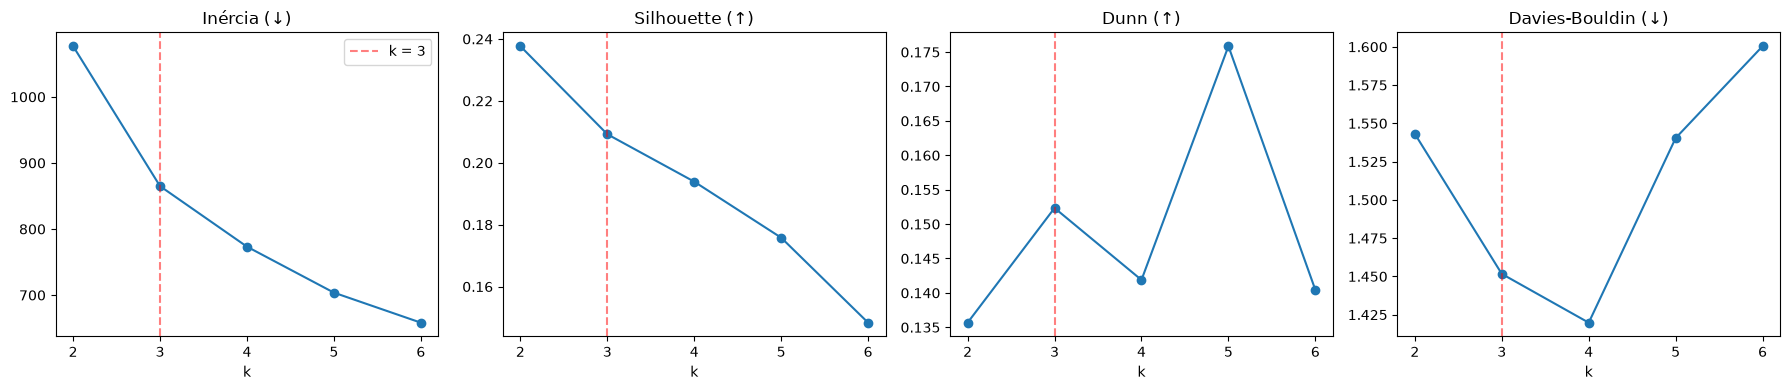

In [29]:
# Avaliação interna - Inércia, Silhouette, Dunn e Davies-Bouldin (K-Means, k = 2 a 6)
def indice_dunn(X, labels):
    """Dunn = menor distância entre clusters / maior diâmetro dentro de um cluster."""
    ids = np.unique(labels)
    diametro_max = max(pdist(X[labels == c]).max() for c in ids if (labels == c).sum() > 1)
    dist_min = min(cdist(X[labels == a], X[labels == b]).min()
                   for i, a in enumerate(ids) for b in ids[i + 1:])
    return dist_min / diametro_max

linhas = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    lab = modelo.labels_
    linhas.append({
        "k": k,
        "Inércia (↓)": modelo.inertia_,
        "Silhouette (↑)": silhouette_score(X_scaled, lab),
        "Dunn (↑)": indice_dunn(X_scaled, lab),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_scaled, lab),
        "Tamanhos": np.bincount(lab).tolist(),
    })

tabela_metricas = pd.DataFrame(linhas).set_index("k")
tabela_metricas["Queda da inércia (%)"] = (-tabela_metricas["Inércia (↓)"].pct_change() * 100).round(1)
print(tabela_metricas.round(3).to_string())

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ["Inércia (↓)", "Silhouette (↑)", "Dunn (↑)", "Davies-Bouldin (↓)"]):
    a.plot(tabela_metricas.index, tabela_metricas[col], marker="o")
    a.axvline(3, color="red", linestyle="--", alpha=0.5, label="k = 3")
    a.set_title(col)
    a.set_xlabel("k")
    a.set_xticks(tabela_metricas.index)
ax[0].legend()
plt.tight_layout()
plt.show()

### Resultado das Métricas

**Cotovelo.** A inércia cai 19,7% de k=2 para k=3, 10,6% de k=3 para k=4 e entre 6,5% e 9,0% nas
etapas seguintes. Não há um cotovelo nítido, mas a maior queda marginal depois do k=2 ocorre ao
chegar a k=3, e a partir daí os ganhos se tornam menores.

**Silhouette.** É máxima em k=2 (0,238) e diminui gradualmente: 0,209 em k=3, 0,194 em k=4 e 0,148
em k=6. Todos os valores são baixos (abaixo de 0,25), o que indica sobreposição entre os grupos.

**Davies-Bouldin.** O menor valor (melhor) ocorre em k=4 (1,420), seguido de perto por k=3 (1,452).
Os valores de k=2 (1,543) e k=5 (1,540) são piores.

**Dunn.** Os valores são baixos e pouco variam (0,136 a 0,176). Isso significa que, em todos os
casos, o maior diâmetro interno dos clusters é muito maior que a distância mínima entre eles:
em k=3, a menor distância entre clusters é de cerca de 1,5 desvio-padrão, enquanto o maior diâmetro
interno chega a 7,7 a 9,8. O maior Dunn aparece em k=5 (0,176), mas isso decorre de um grupo muito
pequeno (11 times-temporada), e não de uma separação melhor. Como o índice depende de apenas dois
pares de pontos extremos, ele é sensível a outliers, e a base tem 18 times-temporada sinalizados na EDA.

**Síntese.** Nenhuma métrica elege o k=3 como o melhor isoladamente: o k=2 vence no Silhouette, o
k=4 no Davies-Bouldin e o k=5 no Dunn. Mas o k=3 fica em **segundo lugar no Silhouette, no
Davies-Bouldin e no Dunn**, e concentra a maior queda de inércia depois do k=2. Como também
produz três grupos equilibrados (41, 35 e 44) e interpretáveis, mantemos o k=3. As métricas
indicam, porém, agrupamentos de qualidade moderada, com sobreposição, o que é compatível com
estilos de jogo que formam um contínuo.

In [30]:
# Avaliação - Estabilidade: K-Means (k=3) com 100 seeds diferentes

resultados = []
for s in range(100):
    km = KMeans(n_clusters=3, random_state=s, n_init=10).fit(X_scaled)
    resultados.append({
        "seed": s,
        "ARI_vs_referencia": adjusted_rand_score(clusters, km.labels_),
        "silhouette": silhouette_score(X_scaled, km.labels_),
        "inercia": km.inertia_,
    })
df_est = pd.DataFrame(resultados)

print(df_est[["ARI_vs_referencia", "silhouette", "inercia"]].describe().round(3))
print("Seeds que reproduzem exatamente a partição de referência:",
      (df_est["ARI_vs_referencia"] > 0.999).sum(), "de", len(df_est))

# Estabilidade por subamostragem: 200 amostras de 80% dos dados
rng = np.random.default_rng(0)
ari_sub = []
for _ in range(200):
    idx = rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False)
    lab_sub = KMeans(n_clusters=3, random_state=0, n_init=10).fit_predict(X_scaled[idx])
    ari_sub.append(adjusted_rand_score(clusters[idx], lab_sub))

print(f"\nSubamostragem 80% | ARI médio: {np.mean(ari_sub):.3f} | "
      f"percentil 5: {np.percentile(ari_sub, 5):.3f} | mínimo: {np.min(ari_sub):.3f}")

       ARI_vs_referencia  silhouette  inercia
count            100.000     100.000  100.000
mean               0.922       0.210  865.008
std                0.061       0.001    0.177
min                0.767       0.207  864.866
25%                0.857       0.209  864.866
50%                0.923       0.211  865.002
75%                1.000       0.211  865.022
max                1.000       0.212  865.895
Seeds que reproduzem exatamente a partição de referência: 30 de 100

Subamostragem 80% | ARI médio: 0.789 | percentil 5: 0.580 | mínimo: 0.456


### Estabilidade do Agrupamento

Rodamos o K-Means (k=3) com 100 sementes diferentes. A qualidade do ajuste é praticamente idêntica
em todas as execuções (inércia entre 864,9 e 865,9; Silhouette entre 0,207 e 0,212), mas a partição
exata não é sempre a mesma: o ARI em relação ao agrupamento de referência tem média de 0,92
(mínimo de 0,77), e 30 das 100 sementes reproduzem exatamente os mesmos grupos. Ou seja, existem
várias soluções quase equivalentes que diferem em alguns times-temporada na fronteira entre
clusters. Nos testes com subamostras de 80% dos dados, o ARI médio foi de 0,79 (percentil 5 em 0,58),
confirmando que a estrutura geral se mantém, mas com certa sensibilidade. Como a base é pequena,
isso é esperado, e reforça que os grupos devem ser lidos como **perfis predominantes**, não como
categorias rígidas.

### Avaliar a Significância Estatística dos Clusters

In [31]:
print("--- Teste ANOVA de Uma Via para Variáveis Táticas ---")
for col in colunas_ajustadas: # colunas_estilo:
    grupos = [X_style[X_style['cluster'] == c][col] for c in range(k_otimo)]
    f_stat, p_val = f_oneway(*grupos)
    print(f"{col:<22} | F-Stat: {f_stat:6.2f} | p-value: {p_val:.4f}")

--- Teste ANOVA de Uma Via para Variáveis Táticas ---
posse_de_bola_aj       | F-Stat:  98.56 | p-value: 0.0000
passes_aj              | F-Stat:  92.50 | p-value: 0.0000
precisao_passes_aj     | F-Stat:  74.23 | p-value: 0.0000
chutes_aj              | F-Stat:  48.32 | p-value: 0.0000
chutes_no_alvo_aj      | F-Stat:  46.03 | p-value: 0.0000
escanteios_aj          | F-Stat:  20.64 | p-value: 0.0000
faltas_aj              | F-Stat:   0.77 | p-value: 0.4651
impedimentos_aj        | F-Stat:   5.34 | p-value: 0.0060
part_chutes_aj         | F-Stat:  31.52 | p-value: 0.0000
part_passes_aj         | F-Stat:  98.42 | p-value: 0.0000
passes_por_posse_aj    | F-Stat:  20.79 | p-value: 0.0000
chutes_por_posse_aj    | F-Stat:  59.36 | p-value: 0.0000


### Interpretação da ANOVA

A ANOVA testa se a média de cada variável difere entre os clusters. Como essas mesmas variáveis
foram usadas para formar os grupos, a significância já era esperada (o teste é, em parte,
circular), e por isso o valor do teste vale menos como "prova" e mais como indicação de **quais
variáveis mais definem cada estilo**. Pelo tamanho do efeito (η²), os clusters separam sobretudo o
bloco de posse e passes (`posse_de_bola_aj` e `part_passes_aj` com η² de 0,63, `passes_aj` 0,61 e
`precisao_passes_aj` 0,56), seguido da finalização (`chutes_por_posse_aj` 0,50, `chutes_aj` 0,45
e `chutes_no_alvo_aj` 0,44). `escanteios_aj`, `part_chutes_aj` e `passes_por_posse_aj` têm efeito
intermediário (0,26 a 0,35).

Duas variáveis diferenciam pouco os clusters: `impedimentos_aj` é estatisticamente significativa
(p = 0,006), mas com efeito pequeno (η² de 0,08), e `faltas_aj` **não diferencia os grupos**
(F = 0,77; p = 0,47; η² de 0,01), isto é, o nível de faltas é parecido nos três estilos. As
faltas, portanto, não ajudam a caracterizar nenhum perfil, e a descrição dos clusters deve se
apoiar nas variáveis de posse, passes e finalização.

         qtd  media  negativos
cluster                       
0         41  0.228          0
1         35  0.227          0
2         44  0.178          2

Silhouette média geral: 0.209


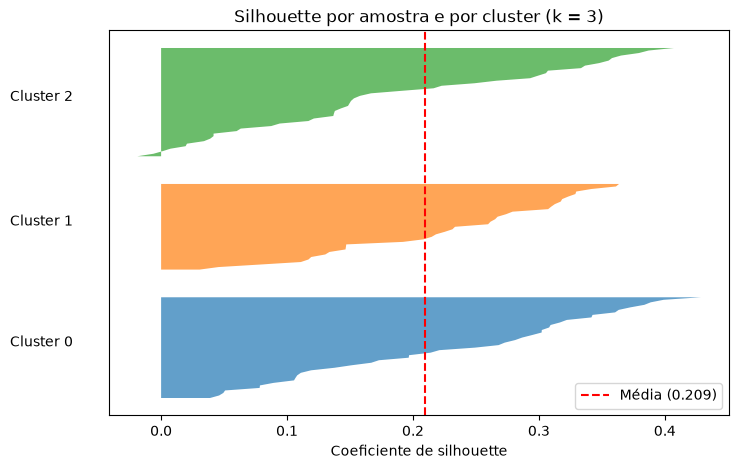

     temporada   time  cluster
85        2019    CSA        2
112       2020  Goias        2


In [32]:
# Silhouette por amostra e por cluster
sil_amostras = silhouette_samples(X_scaled, clusters)

resumo_sil = (pd.DataFrame({"cluster": clusters, "silhouette": sil_amostras})
              .groupby("cluster")["silhouette"]
              .agg(qtd="count", media="mean", negativos=lambda s: (s < 0).sum()))
print(resumo_sil.round(3))
print(f"\nSilhouette média geral: {sil_amostras.mean():.3f}")

# Gráfico de silhouette por amostra
fig, ax = plt.subplots(figsize=(8, 5))
y_inf = 10
for c in range(k_otimo):
    valores = np.sort(sil_amostras[clusters == c])
    y_sup = y_inf + len(valores)
    ax.fill_betweenx(np.arange(y_inf, y_sup), 0, valores, alpha=0.7)
    ax.text(-0.12, y_inf + 0.5 * len(valores), f"Cluster {c}")
    y_inf = y_sup + 10
ax.axvline(sil_amostras.mean(), color="red", linestyle="--", label=f"Média ({sil_amostras.mean():.3f})")
ax.set_xlabel("Coeficiente de silhouette")
ax.set_yticks([])
ax.set_title("Silhouette por amostra e por cluster (k = 3)")
ax.legend()
plt.show()

# Times-temporada com silhouette negativa (na fronteira entre clusters)
print(df_performance.iloc[np.where(sil_amostras < 0)[0]][["temporada", "time", "cluster"]])

### Coesão de Cada Cluster

A Silhouette média é de 0,228 no cluster 0 (41 times-temporada), 0,227 no cluster 1 (35) e 0,178 no
cluster 2 (44). Os clusters 0 e 1 têm coesão semelhante, enquanto o cluster 2 é o mais disperso e o
que mais se sobrepõe aos vizinhos. Apenas 2 dos 120 times-temporada têm silhouette negativa (CSA
2019 e Goiás 2020, ambos no cluster 2), com valores muito próximos de zero (-0,006 e -0,019), ou
seja, estão praticamente sobre a fronteira entre dois grupos. *(Os nomes dos clusters são definidos
na Etapa 6: 0 = Propositivo / Controle de Posse, 1 = Ataque Direto / Transição Rápida e
2 = Reativo / Bloco Baixo.)*

### Síntese da Avaliação

As métricas internas (Silhouette de 0,209, Davies-Bouldin de 1,45 e Dunn de 0,15 em k=3) indicam
agrupamentos de qualidade **moderada**, com sobreposição entre os grupos, algo esperado em estilos
de jogo, que formam mais um contínuo do que categorias rígidas. Ainda assim, há evidências de que a
estrutura não é aleatória: apenas 2 dos 120 times-temporada têm silhouette negativa (e ambos
muito próximos de zero); o ajuste do modelo é praticamente idêntico entre 100 sementes (ARI médio de
0,92 e Silhouette entre 0,207 e 0,212); o método de Ward recupera, sem divergência, o grupo de
maior posse; e a ANOVA mostra que as variáveis de posse, passes e finalização diferenciam
claramente os clusters. As fragilidades são a fronteira entre os dois grupos de menor posse (ARI de
0,47 com o Ward em k=3), o cluster 2, o menos coeso, e a sensibilidade a subamostras (ARI médio de
0,79). Por isso, os clusters são interpretados como **perfis predominantes**, e não como categorias
rígidas.

# Etapa 6: Descrição de Cluster

### Profilaxia Tática e Mapeamento de Retorno vs. Risco

In [33]:
# 1. Perfil Tatico de cada Cluster (Medias despadronizadas)
perfil_tatico = X_style.groupby('cluster').mean().T
print("--- Média das Métricas Táticas por Cluster ---")
print(perfil_tatico)

# 2. Retorno e Risco por Cluster (Relatorio para o CEO)
relatorio_ceo = df_performance.groupby('cluster').agg({
    'time': 'count',
    'pts_jogo': 'mean',
    'pct_vitorias': 'mean',
    'saldo_jogo': 'mean',
    'risco_derrota_2mais': 'mean',
    'risco_pts_dp': 'mean'
}).rename(columns={'time': 'qtd_times_temporada'})

print("\n--- Desempenho e Risco por Estilo de Jogo ---")
print(relatorio_ceo)

--- Média das Métricas Táticas por Cluster ---
cluster                       0           1           2
posse_de_bola_aj      50.102448   54.197544   46.610010
passes_aj            432.173401  468.885464  382.595853
precisao_passes_aj    80.882342   82.584251   78.331876
chutes_aj             11.929731   14.186307   13.350916
chutes_no_alvo_aj      3.835322    4.795710    4.304571
escanteios_aj          4.840588    5.750255    5.261531
faltas_aj             14.738008   14.587456   14.974989
impedimentos_aj        1.380456    1.461504    1.610169
part_chutes_aj        47.262604   53.334546   49.905448
part_passes_aj        50.195692   54.116207   46.587945
passes_por_posse_aj    8.653716    8.654594    8.253114
chutes_por_posse_aj    0.240555    0.264737    0.290677

--- Desempenho e Risco por Estilo de Jogo ---
         qtd_times_temporada  pts_jogo  pct_vitorias  saldo_jogo  \
cluster                                                            
0                         41  1.245828    

### Inversão da Padronização e Média por Cluster

In [34]:
# 1. Calcular a média das variáveis táticas ajustadas (_aj) por cluster na escala original
perfil_tatico_medio = X_style.groupby('cluster').mean().T

# 2. Calcular a média geral do campeonato (2018-2023) para comparação
perfil_tatico_medio['Média Geral'] = X_style.drop(columns='cluster').mean()

# 3. Exibir o comparativo tático
print(perfil_tatico_medio.round(2))

cluster                   0       1       2  Média Geral
posse_de_bola_aj      50.10   54.20   46.61        50.02
passes_aj            432.17  468.89  382.60       424.70
precisao_passes_aj    80.88   82.58   78.33        80.44
chutes_aj             11.93   14.19   13.35        13.11
chutes_no_alvo_aj      3.84    4.80    4.30         4.29
escanteios_aj          4.84    5.75    5.26         5.26
faltas_aj             14.74   14.59   14.97        14.78
impedimentos_aj        1.38    1.46    1.61         1.49
part_chutes_aj        47.26   53.33   49.91        50.00
part_passes_aj        50.20   54.12   46.59        50.02
passes_por_posse_aj    8.65    8.65    8.25         8.51
chutes_por_posse_aj    0.24    0.26    0.29         0.27


**Nota de leitura dos nomes.** Os rótulos foram atribuídos antes dos testes de desempenho. Cada nome
deve ser lido pela definição baseada nas médias: "Ataque Direto" = maior volume ofensivo (chutes,
chutes no alvo e escanteios), que também é o grupo de maior posse e passes; "Propositivo" = circula
a bola com passes e precisão acima da média, mas é o grupo que menos finaliza; "Reativo" = menor
posse e passes, com finalização mais direta.

In [35]:
# 1. Definir o dicionário com base na análise das médias
rotulos_taticos = {
    0: 'Propositivo / Controle de Posse',
    1: 'Ataque Direto / Transição Rápida',
    2: 'Reativo / Bloco Baixo'
}

# 2. Criar a coluna textual nos DataFrames
df_performance['nome_cluster'] = df_performance['cluster'].map(rotulos_taticos)
X_style['nome_cluster'] = X_style['cluster'].map(rotulos_taticos)

# Exemplo de visualização com nomes amigáveis para o CEO
df_performance.groupby('nome_cluster')[['pts_jogo', 'pct_vitorias', 'risco_derrota_2mais']].mean()

,pts_jogo,pct_vitorias,risco_derrota_2mais
nome_cluster,,,
Ataque Direto / Transição Rápida,1.505263,0.417293,0.121053
Propositivo / Controle de Posse,1.245828,0.317715,0.155327
Reativo / Bloco Baixo,1.352871,0.355861,0.154306


In [36]:
# Listar as equipas e temporadas pertencentes a cada cluster
for c in sorted(df_performance['nome_cluster'].unique()):
    equipas_cluster = df_performance[df_performance['nome_cluster'] == c][['temporada', 'time']].values
    print(f"\n--- CLUSTER {c} ({len(equipas_cluster)} equipas-temporada) ---")
    for temp, time in equipas_cluster[:8]: # Exibe os primeiros 8 exemplos
        print(f"• {time} ({temp})")


--- CLUSTER Ataque Direto / Transição Rápida (35 equipas-temporada) ---
• Athletico-PR (2018)
• Atletico-MG (2018)
• Flamengo (2018)
• Gremio (2018)
• Athletico-PR (2019)
• Atletico-MG (2019)
• Cruzeiro (2019)
• Flamengo (2019)

--- CLUSTER Propositivo / Controle de Posse (41 equipas-temporada) ---
• America-MG (2018)
• Corinthians (2018)
• Cruzeiro (2018)
• Fluminense (2018)
• Internacional (2018)
• Santos (2018)
• Sport (2018)
• Vasco (2018)

--- CLUSTER Reativo / Bloco Baixo (44 equipas-temporada) ---
• Bahia (2018)
• Botafogo-RJ (2018)
• Ceara (2018)
• Chapecoense (2018)
• Palmeiras (2018)
• Parana (2018)
• Sao Paulo (2018)
• Bahia (2019)


### Cruzamento com a Matriz de Retorno e Risco

In [37]:
# Tabela consolidada de Retorno e Risco por Cluster
matriz_retorno_risco = df_performance.groupby('nome_cluster').agg(
    qtd_equipas=('time', 'count'),
    pts_jogo_medio=('pts_jogo', 'mean'),
    pct_vitorias_media=('pct_vitorias', 'mean'),
    saldo_jogo_medio=('saldo_jogo', 'mean'),
    risco_goleada_media=('risco_derrota_2mais', 'mean'), # Proporção de derrotas por 2+ golos
    irregularidade_pts=('risco_pts_dp', 'mean'),        # Desvio-padrão de pontos
    pct_sem_marcar_medio=('pct_sem_marcar', 'mean'),
    pct_sem_sofrer_medio=('pct_sem_sofrer', 'mean')
).reset_index()

print(matriz_retorno_risco.round(3))

                       nome_cluster  qtd_equipas  pts_jogo_medio  \
0  Ataque Direto / Transição Rápida           35           1.505   
1   Propositivo / Controle de Posse           41           1.246   
2             Reativo / Bloco Baixo           44           1.353   

   pct_vitorias_media  saldo_jogo_medio  risco_goleada_media  \
0               0.417             0.227                0.121   
1               0.318            -0.164                0.155   
2               0.356            -0.028                0.154   

   irregularidade_pts  pct_sem_marcar_medio  pct_sem_sofrer_medio  
0               1.283                 0.265                 0.323  
1               1.234                 0.353                 0.303  
2               1.251                 0.302                 0.303  


### Construção dos Gráficos de Perfilamento (Radar Chart ou Bar Plot)

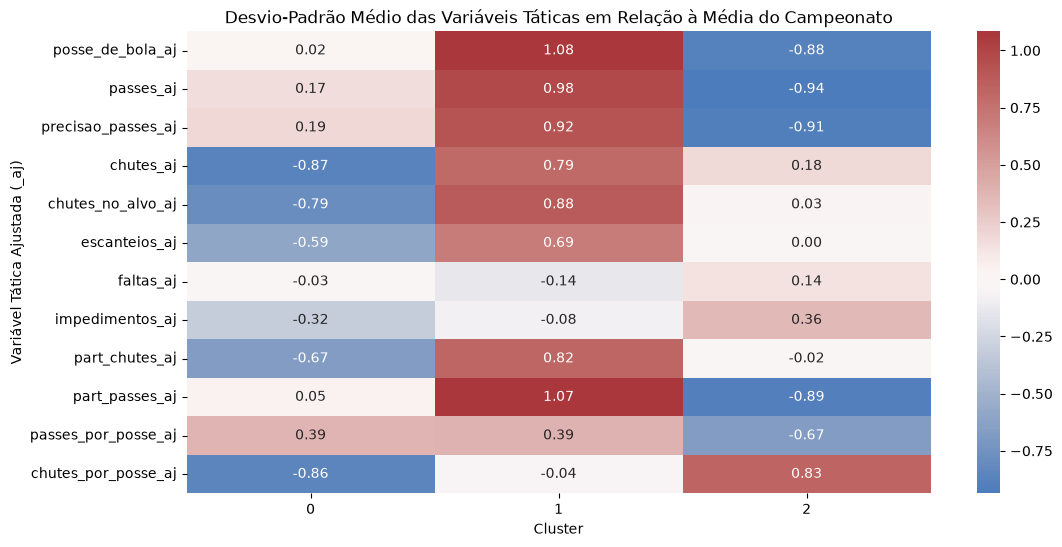

In [38]:
# Normalizar as médias para visualização em barras comparativas (Z-Score médio por cluster)
X_scaled_df = pd.DataFrame(X_scaled, columns=colunas_ajustadas)# colunas_estilo)
X_scaled_df['cluster'] = clusters

plt.figure(figsize=(12, 6))
cluster_vis = X_scaled_df.groupby('cluster').mean().T
sns.heatmap(cluster_vis, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Desvio-Padrão Médio das Variáveis Táticas em Relação à Média do Campeonato")
plt.xlabel("Cluster")
plt.ylabel("Variável Tática Ajustada (_aj)")
plt.show()

In [39]:
# Tratativa definimos a ordem de exibição dos nomes dos grupos para facilitar
# as próximas análises.

ordem_nomes = (df_performance.groupby("nome_cluster")["pts_jogo"].mean()
               .sort_values(ascending=False).index.tolist())
paleta = ["#1f77b4", "#2ca02c", "#d62728"]
cores_clusters = dict(zip(ordem_nomes, paleta))

df_performance["tecnico_principal"] = df_season_rec["tecnico_principal"]
df_performance["n_tecnicos"] = df_season_rec["n_tecnicos"]

print(ordem_nomes)

['Ataque Direto / Transição Rápida', 'Reativo / Bloco Baixo', 'Propositivo / Controle de Posse']


### Descrição Detalhada dos Clusters

**Cluster 1: Ataque Direto / Transição Rápida (35 times-temporada).** É o estilo de maior controle e de maior
volume ofensivo: posse de 54,2% (+1,08 desvio-padrão), 469 passes e 82,6% de precisão, além do maior
número de chutes (14,2), chutes no alvo (4,8) e escanteios (5,75). Domina a partida e finaliza com
frequência. Tem o melhor desempenho: 1,51 ponto por jogo, 41,7% de vitórias e saldo de +0,23 gol
por jogo. Reúne os clubes de maior investimento do período, como Flamengo (6 das 6 temporadas)
e Atlético-MG (5 das 6), e três campeões (Flamengo 2019 e 2020 e Atlético-MG 2021).

**Cluster 2: Reativo / Bloco Baixo (44 times-temporada).** É o oposto no controle da bola: menor
posse (46,6%, -0,88 desvio-padrão), menos passes (383) e menor precisão (78,3%). Em compensação,
finaliza de forma mais direta: maior número de chutes por posse (0,29, +0,83 desvio-padrão), menos
passes por posse e o maior número de impedimentos (1,61). Cede a bola e ataca em poucos toques. O
desempenho é intermediário (1,35 ponto por jogo, 35,6% de vitórias, saldo próximo de zero), mas com
três campeões: o Palmeiras de 2018, 2022 e 2023. O Palmeiras ficou nas seis temporadas neste estilo,
assim como Ceará (5 de 5) e Goiás (4 de 4).

**Cluster 0: Propositivo / Controle de Posse (41 times-temporada).** Tem posse na média do campeonato (50,1%) e boa
circulação (432 passes, 80,9% de precisão), mas é o grupo que **menos finaliza**: 11,9 chutes, 3,8 no
alvo e apenas 0,24 chute por posse (-0,86 desvio-padrão). Ou seja, tem a bola, mas a converte
pouco em ameaça. É o pior desempenho: 1,25 ponto por jogo, 31,8% de vitórias e saldo de -0,16, sem
nenhum campeão. O Corinthians esteve neste estilo em todas as seis temporadas.

**Diferenças e interpretação.** Os eixos que mais separam os clusters são o controle da bola
(posse e passes) e a finalização. O contraste mais relevante é entre os clusters 1 e 0: ambos
têm boa circulação de bola, mas o primeiro a transforma em finalizações e o segundo não. Isso
sugere que **a posse, por si só, não está associada a bons resultados; o que importa é a capacidade
de transformá-la em finalizações**. O estilo reativo mostra que também é possível ter bons resultados
com pouca posse, desde que a finalização seja direta e eficiente.

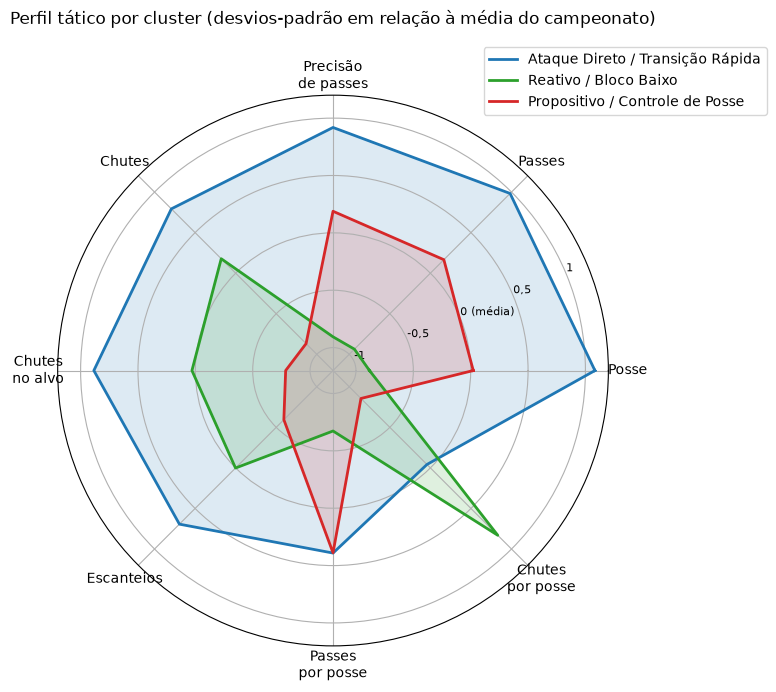

                                  posse_de_bola_aj  passes_aj  \
cluster                                                         
Propositivo / Controle de Posse               0.02       0.17   
Ataque Direto / Transição Rápida              1.08       0.98   
Reativo / Bloco Baixo                        -0.88      -0.94   

                                  precisao_passes_aj  chutes_aj  \
cluster                                                           
Propositivo / Controle de Posse                 0.19      -0.87   
Ataque Direto / Transição Rápida                0.92       0.79   
Reativo / Bloco Baixo                          -0.91       0.18   

                                  chutes_no_alvo_aj  escanteios_aj  \
cluster                                                              
Propositivo / Controle de Posse               -0.79          -0.59   
Ataque Direto / Transição Rápida               0.88           0.69   
Reativo / Bloco Baixo                          0.03       

In [40]:
vars_radar = ["posse_de_bola_aj", "passes_aj", "precisao_passes_aj", "chutes_aj",
              "chutes_no_alvo_aj", "escanteios_aj", "passes_por_posse_aj", "chutes_por_posse_aj"]
rotulos_radar = ["Posse", "Passes", "Precisão\nde passes", "Chutes", "Chutes\nno alvo",
                 "Escanteios", "Passes\npor posse", "Chutes\npor posse"]

z_df = pd.DataFrame(X_scaled, columns=colunas_ajustadas)
z_df["cluster"] = clusters
medias_z = z_df.groupby("cluster")[vars_radar].mean()
medias_z.index = medias_z.index.map(rotulos_taticos)

angulos = np.linspace(0, 2 * np.pi, len(vars_radar), endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for nome in ordem_nomes:
    valores = medias_z.loc[nome].tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, linewidth=2, label=nome, color=cores_clusters[nome])
    ax.fill(angulos, valores, alpha=0.15, color=cores_clusters[nome])

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(rotulos_radar, fontsize=10)
ax.set_ylim(-1.2, 1.2)
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_yticklabels(["-1", "-0,5", "0 (média)", "0,5", "1"], fontsize=8)
ax.set_title("Perfil tático por cluster (desvios-padrão em relação à média do campeonato)", pad=25)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

print(medias_z.round(2))

In [41]:
contagem = pd.crosstab(df_performance["time"], df_performance["nome_cluster"])
total_temporadas = contagem.sum(axis=1)

for nome in ordem_nomes:
    top = contagem[nome].sort_values(ascending=False).head(6)
    print(f"\n--- {nome} ({int(contagem[nome].sum())} times-temporada) ---")
    for time, n in top.items():
        print(f"• {time}: {n} de {total_temporadas[time]} temporadas")

# Clubes que ficaram sempre no mesmo cluster (identidade estável), com pelo menos 4 temporadas
estaveis = contagem[(contagem.max(axis=1) == total_temporadas) & (total_temporadas >= 4)]
print("\n--- Clubes com estilo estável (todas as temporadas no mesmo cluster, mín. 4) ---")
print(estaveis.idxmax(axis=1).rename("cluster").to_frame().join(total_temporadas.rename("temporadas")))


--- Ataque Direto / Transição Rápida (35 times-temporada) ---
• Flamengo: 6 de 6 temporadas
• Atletico-MG: 5 de 6 temporadas
• Sao Paulo: 3 de 6 temporadas
• Fluminense: 3 de 6 temporadas
• Gremio: 3 de 5 temporadas
• Athletico-PR: 2 de 6 temporadas

--- Reativo / Bloco Baixo (44 times-temporada) ---
• Palmeiras: 6 de 6 temporadas
• Ceara: 5 de 5 temporadas
• Goias: 4 de 4 temporadas
• Bahia: 3 de 5 temporadas
• America-MG: 3 de 4 temporadas
• Fortaleza: 3 de 5 temporadas

--- Propositivo / Controle de Posse (41 times-temporada) ---
• Corinthians: 6 de 6 temporadas
• Santos: 3 de 6 temporadas
• Sport: 3 de 3 temporadas
• Internacional: 3 de 6 temporadas
• Fluminense: 3 de 6 temporadas
• Vasco: 2 de 4 temporadas

--- Clubes com estilo estável (todas as temporadas no mesmo cluster, mín. 4) ---
                                      cluster  temporadas
time                                                     
Ceara                   Reativo / Bloco Baixo           5
Corinthians   Proposit

Os clubes mais frequentes de cada cluster são: Flamengo (6), Atlético-MG (5), São Paulo, Fluminense
e Grêmio (3 cada) no "Ataque Direto / Transição Rápida"; Palmeiras (6), Ceará (5), Goiás (4) e Bahia, América-MG e Fortaleza
(3) no "Reativo / Bloco Baixo"; e Corinthians (6), Santos, Sport, Internacional e Fluminense (3) no "Propositivo / Controle de Posse".
Cinco clubes mantiveram o mesmo estilo em todas as temporadas (Flamengo, Palmeiras, Corinthians,
Ceará e Goiás), o que indica que, em vários casos, o estilo funciona como uma identidade do clube.
Outros, como Athletico-PR e Internacional, oscilaram entre os três perfis.

### Classificação Final por Estilo

Os times do estilo **Ataque Direto / Transição Rápida** terminam, em média, na 8,5ª posição, e 34,3% deles ficam entre
os quatro primeiros (8,6% campeões e 25,7% no G4), contra 14,3% no Z4. O **Reativo / Bloco Baixo** tem posição
média de 10,6, com 20,5% no G4 ou título (incluindo os três títulos do Palmeiras) e 20,5% no Z4. A
**Propositivo / Controle de Posse** é o perfil mais fraco: posição média de 12,1, nenhum campeão, apenas 7,3%
no G4 e 24,4% no Z4. Como há poucos campeões e G4 (24 casos nos 120 times-temporada), essas
proporções são indicativas, e o teste qui-quadrado não é significativo (p ≈ 0,15). A evidência
mais robusta continua sendo a dos pontos por jogo.

Contagem:
faixa_final                       Campeão  G4  Meio de tabela  Z4
nome_cluster                                                     
Ataque Direto / Transição Rápida        3   9              18   5
Reativo / Bloco Baixo                   3   6              26   9
Propositivo / Controle de Posse         0   3              28  10

Percentual (por linha):
faixa_final                       Campeão    G4  Meio de tabela    Z4
nome_cluster                                                         
Ataque Direto / Transição Rápida      8.6  25.7            51.4  14.3
Reativo / Bloco Baixo                 6.8  13.6            59.1  20.5
Propositivo / Controle de Posse       0.0   7.3            68.3  24.4

Posição final média por cluster:
nome_cluster
Ataque Direto / Transição Rápida     8.5
Reativo / Bloco Baixo               10.6
Propositivo / Controle de Posse     12.1
Name: posicao_final, dtype: float64

% em Campeão + G4:
nome_cluster
Ataque Direto / Transição Rápida    34.3
Reati

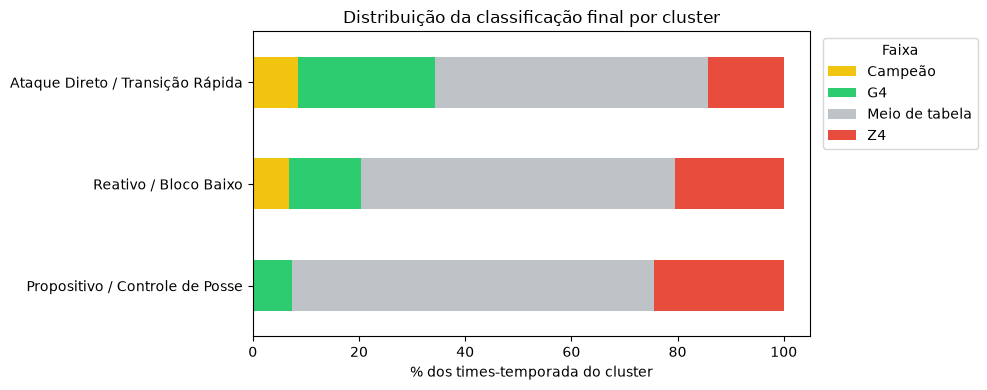

In [42]:
ct_abs = pd.crosstab(df_performance["nome_cluster"], df_performance["faixa_final"]).reindex(ordem_nomes)
ct_pct = (pd.crosstab(df_performance["nome_cluster"], df_performance["faixa_final"], normalize="index")
          .reindex(ordem_nomes) * 100)

print("Contagem:")
print(ct_abs)
print("\nPercentual (por linha):")
print(ct_pct.round(1))

df_performance["top4"] = df_performance["posicao_final"] <= 4
print("\nPosição final média por cluster:")
print(df_performance.groupby("nome_cluster")["posicao_final"].mean().reindex(ordem_nomes).round(1))
print("\n% em Campeão + G4:")
print((df_performance.groupby("nome_cluster")["top4"].mean().reindex(ordem_nomes) * 100).round(1))

cores_faixa = ["#f1c40f", "#2ecc71", "#bdc3c7", "#e74c3c"]
ax = ct_pct.plot(kind="barh", stacked=True, figsize=(10, 4), color=cores_faixa)
ax.set_xlabel("% dos times-temporada do cluster")
ax.set_ylabel("")
ax.set_title("Distribuição da classificação final por cluster")
ax.legend(title="Faixa", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Etapa 7: Conclusões

## Resumo dos resultados

| Estilo | Times-temporada | Pontos por jogo | % vitórias | Saldo por jogo | Risco de goleada | Posição média | % Campeão + G4 | % Z4 | Nº médio de técnicos |
|---|---|---|---|---|---|---|---|---|---|
| Ataque Direto / Transição Rápida | 35 | 1,51 | 41,7% | +0,23 | 12,1% | 8,5 | 34,3% | 14,3% | 2,8 |
| Reativo / Bloco Baixo | 44 | 1,35 | 35,6% | -0,03 | 15,4% | 10,6 | 20,5% | 20,5% | 3,2 |
| Propositivo / Controle de Posse | 41 | 1,25 | 31,8% | -0,16 | 15,5% | 12,1 | 7,3% | 24,4% | 3,5 |

*(Nota de leitura dos nomes: "Ataque Direto" = maior volume ofensivo, com a maior posse e passes;
"Propositivo" = circula a bola, mas é o grupo que menos finaliza; "Reativo" = menor posse e passes,
com finalização mais direta.)*

## Respostas às perguntas do estudo

**1. Quais são os perfis de jogo dominantes no Brasileirão?**
Identificamos três estilos, com o K-Means (k=3) sobre 12 métricas táticas de 120 times-temporada
(2018-2023): o **Ataque Direto / Transição Rápida** (35), que combina o maior controle da bola
(54,2% de posse) com o maior volume de finalização; o **Reativo / Bloco Baixo** (44), de menor
posse (46,6%) e finalização mais direta; e o **Propositivo / Controle de Posse** (41), que
circula a bola, mas é o que menos finaliza (11,9 chutes por jogo).

**2. Como os times se comportam taticamente quando desconsideramos a disparidade de força (Elo)?**
Usando métricas ajustadas pelo Elo do adversário e pelo mando de campo, a estrutura de três
estilos se mantém. Ainda assim, o estilo não é independente do clube: Flamengo (6 de 6 temporadas)
e Atlético-MG (5 de 6) concentram-se no Ataque Direto, Palmeiras (6 de 6), Ceará (5 de 5) e Goiás
(4 de 4) no Reativo, e Corinthians (6 de 6) no Propositivo. Isso mostra que o estilo funciona,
em muitos casos, como uma identidade do clube, e que o ajuste usado não elimina por completo a
influência da qualidade do próprio elenco.

**3. Qual o binômio retorno × risco de cada estilo?**
O **Ataque Direto** tem o melhor retorno (1,51 ponto por jogo, 41,7% de vitórias, saldo de +0,23)
e também o menor risco de goleada (12,1% dos jogos com derrota por 2+ gols). O **Reativo** tem retorno
intermediário (1,35 ponto por jogo) e o **Propositivo** o pior (1,25). As diferenças de retorno são
estatisticamente significativas, com a diferença clara entre Ataque Direto e Propositivo. O **risco de goleada não difere de forma significativa** entre os estilos (p = 0,16),
e a irregularidade de pontos é praticamente igual (desvio-padrão entre 1,23 e 1,28). Portanto, o
que separa os estilos é sobretudo o **retorno**, e não o risco. O efeito é de tamanho pequeno a
moderado: o estilo explica cerca de 8% a 11% da variação dos resultados.

## O que os dados indicam sobre cada estilo

- **Maior retorno e menor risco: Ataque Direto.** Reúne controle da bola e volume de finalização,
  tem 34,3% dos times entre campeão e G4, três títulos (Flamengo 2019 e 2020 e Atlético-MG 2021)
  e a menor taxa de goleadas.
- **Alternativa viável: Reativo.** Mesmo com pouca posse, conquistou três títulos (Palmeiras 2018,
  2022 e 2023), o que mostra que não é preciso dominar a bola para vencer, desde que a finalização
  seja direta. O retorno médio é intermediário, com 20,5% dos times no G4 ou no título e 20,5% no Z4.
- **Estilo a evitar: Propositivo.** Tem boa circulação de bola, mas finaliza pouco: menor retorno,
  nenhum campeão e a maior taxa de rebaixamento (24,4%). Na amostra, a finalização é a variável de
  estilo mais ligada aos pontos (chutes no alvo, correlação de 0,43), enquanto a posse tem relação
  fraca (0,09).

## Recomendações para a diretoria

1. **Priorizar a capacidade de finalizar, mais do que a posse.** Em vez de buscar "jogar com a
   bola", buscar "transformar a bola em chutes no alvo". Esse é o fator mais associado a pontos
   nesta análise.
2. **Estilo de referência: Ataque Direto**, se o elenco comportar controle de bola e volume
   ofensivo. É o perfil com melhor retorno e menor risco.
3. **Se o elenco não sustentar a posse, o Reativo / Bloco Baixo é uma alternativa legítima**, com
   campeões e sem dependência de dominar a bola. O ponto crítico é manter finalização eficiente.
4. **Evitar o perfil Propositivo**, ou seja, circular a bola sem finalizar, que reúne o pior retorno.
5. **Critérios para escolher o treinador:** priorizar profissionais com histórico consistente no
   estilo desejado (por exemplo, os 4 técnicos que mantiveram o mesmo estilo em todas as temporadas
   analisadas, dois deles também em clubes diferentes) e avaliar não só a posse de suas equipes,
   mas principalmente a finalização.
6. **Valorizar a estabilidade da comissão técnica.** Equipes com menos trocas de técnico tiveram
   desempenho melhor, embora a causalidade não possa ser afirmada.
7. **Acompanhar indicadores durante a temporada**, como chutes no alvo e chutes por posse, para
   verificar se o time está no estilo planejado.